# Part 2: shared control of the BCI wheelchair

This continues `src/part1_decoder.ipynb`. Run Part 1 first: it writes the two files this notebook starts from.

**Where Part 1 stopped.** Part 1 trained a CSP + LDA decoder on day 1, calibrated it with Platt scaling, and tested it on day 2. Its results per subject are in `results/part1/summary_by_subject.csv`: a mean calibrated accuracy of 0.443 (chance is 0.25), a mean κ of 0.258, a measured decision latency for every trial, and on average 53% of trials censored. Subject 5 is below chance.

**What this notebook adds.** Everything after the decoder, one section each:

| section | part of the system | question |
|---|---|---|
| 2 | BCI channel model | How often is the decoder wrong, in which direction, how late, how confident? |
| 3 | Plant models | What is being controlled, and where does it drive? |
| 4 | Operator model | Who is steering? |
| 5 | Autopilot and arbitration | Who gets control, and when? |
| 6 | Simulation study | Which way of sharing control works? |
| 7 | Stability analysis | How much delay can the loop take? |

All of Part 2's code is in the cells below; unlike Part 1, it imports nothing from `src/`. It was taken from the original research simulator that produced `results/part2/episodes.csv` (that code is not part of this repository). The long docstrings have moved into the text; the logic and the order of the random-number calls are unchanged, and Section 6.4 checks this by reproducing drives from the saved log.

### The answer first

| how control is shared | reaches the goal | crashes |
|---|---|---|
| the user drives alone | 12% | 88% |
| the autopilot drives alone | 100% | 0% |
| **adaptive**: user's share = confidence × (1 − risk) | **99.6%** | **0.4%** |

1. **The user cannot drive the chair alone.** Part of that is the decoder, which is wrong 56% of the time. Part of it is the simulated user, who aims straight at the goal and does not steer around obstacles. Only the corridor isolates the decoder's effect.
2. **Adaptive sharing recovers almost all of the autopilot's safety** while giving the user about 12% of the control. It is *not better* than the autopilot alone.
3. **Risk does the work, not confidence.** Without the risk term, adaptive loses 20 points of success. With a perfect confidence signal instead, nothing changes.
4. **The delay limit is derived exactly and checked three ways, but it is not what limits this system.** The crashes happen at settings where delay cannot cause instability. The limit is the decoder's *errors*, not its *latency*.

### What this notebook reads, and what it writes

It reads three files (all paths are relative to the repository root, the folder that holds `README.md`):

- `results/part1/summary_by_subject.csv`: Part 1's per-subject results.
- `results/part1/decoder_traces.csv`: Part 1's decoder, **trial by trial** (2,592 rows), also written by Part 1. Section 2 checks that it agrees with the per-subject summary.
- `results/part2/episodes.csv`: the saved log of the full experiment, 32,400 simulated drives, made by the original simulator with the same code as this notebook (Section 6.4 checks that).

It writes:

- `results/part2/figures/`: every figure, numbered by section;
- `results/part2/tables/`: the main result tables as CSV;
- `logs/part2_run.log`: the verification checks and headline numbers from the run.

The full experiment took about 39 minutes on 18 CPU cores, so by default Section 6 re-simulates a sample from every condition with the code in this notebook, checks it against the saved log, and then analyses the saved log. Set `RUN_FULL_MAIN_GRID = True` below to re-run the whole 3,240-drive main comparison here instead (about 10 minutes on a fast machine, longer on a laptop).

The whole notebook runs in about a minute. Packages: see `requirements.txt`. `control` is optional: without it, the one check that needs it is skipped.

In [1]:
%matplotlib inline
import copy
import heapq
import math
import os
import time
import zlib
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from scipy.linalg import expm, solve_continuous_are
from sklearn.metrics import cohen_kappa_score, roc_auc_score

SEED = 20260901  # same root seed as Part 1

# work from the submission root, wherever Jupyter started
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)

# inputs
PART1_SUMMARY = Path("results/part1/summary_by_subject.csv")   # from Part 1
TRACES_CSV = Path("results/part1/decoder_traces.csv")           # from Part 1
EPISODES_CSV = Path("results/part2/episodes.csv")               # saved full experiment

# outputs
FIGS = Path("results/part2/figures")
TABLES = Path("results/part2/tables")
LOGS = Path("logs")
for folder in (FIGS, TABLES, LOGS):
    folder.mkdir(parents=True, exist_ok=True)

for p in (PART1_SUMMARY, TRACES_CSV, EPISODES_CSV):
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Run src/part1_decoder.ipynb first; it writes results/part1/.")


def save_fig(name):
    # save, then show inline
    plt.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

RUN_FULL_MAIN_GRID = False  # True: re-run all 3,240 main drives

# Part 1's colours, plus three more
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
YELLOW, VIOLET, RED, INK = "#eda100", "#4a3aa7", "#e34948", "#0b0b0b"
COLORS = {"manual_only": BLUE, "autonomy_only": ORANGE, "fixed_blend": GREEN,
          "confidence_only": YELLOW, "adaptive": VIOLET, "safety_filter": RED}
VARIANTS = tuple(COLORS)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.4, "font.size": 9})

import scipy, sklearn, matplotlib
print(f"numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

numpy 2.5.2 | scipy 1.18.1 | pandas 3.0.5 | scikit-learn 1.9.0 | matplotlib 3.11.1


## 1. Parameters

The project keeps a strict rule: **every number lives in one place**. No gain, limit or threshold is typed directly into the code. They are all in this one dictionary, copied from the original simulator's two configuration files (`default.yaml` and `environments.yaml`). Those files are not in this repository; this dictionary is the complete copy. Units are SI throughout: metres, seconds, radians.

Code reads a value by its dotted path, for example `cfg["plants.unicycle.tau_v"]`, so every line of code names exactly which setting it uses.

`with_overrides` matters for the ablations in Section 6. It returns a **new** config instead of editing the old one. Otherwise an ablation such as "remove the delay" could leak into every run after it, a bug that is very hard to spot in averaged results. It also refuses to override a key that doesn't exist, so a mistyped ablation fails loudly instead of quietly doing nothing and getting reported as "no effect".

In [2]:
CONFIG = {
    "meta": {"seed": SEED},
    "decoder": {"oracle_confidence": False},          # ablation switch
    "command_error": {
        "iid_override": False,                         # ablation switch
        "fit": {"smoothing": 0.5},
        "validation": {"n_synthetic_sequences": 200, "burst_hist_max_len": 12},
        "latency": {"min_s": 0.1, "max_s": 3.0},
    },
    "confidence": {"prior": 0.25, "age_decay": {"enabled": False, "tau_s": 1.5}},
    "plants": {
        "dt": 0.02,                                    # 50 Hz
        "double_integrator": {"damping": 1.0, "u_max": 6.0, "workspace_radius": 2.0},
        "unicycle": {"tau_v": 0.30, "tau_w": 0.20, "v_max": 1.2, "v_min": -0.4,
                     "w_max": 1.5, "dv_max": 1.0, "dw_max": 3.0,
                     "collision_radius": 0.35, "k_heading": 2.0,
                     "speed_gate_power": 2.0},
    },
    "operator": {"kp": 4.0, "kd": 2.0, "tau_h": 0.20, "decision_interval_s": 2.0},
    "control": {
        "lqr": {"q_position": 10.0, "q_velocity": 1.0, "r_effort": 1.0},
        "dwa": {"window_dt": 0.25, "plan_period_s": 0.10, "predict_horizon_s": 1.5,
                "n_v_samples": 7, "n_w_samples": 21, "weight_heading": 0.8,
                "weight_clearance": 0.4, "weight_velocity": 0.2,
                "clearance_cap": 2.0, "safety_margin": 0.05, "goal_tolerance": 0.35},
        "risk": {"force_zero": False, "horizon_s": 3.0, "floor_s": 0.5,
                 "smoothing_tau": 0.30},
        "arbitration": {
            "force_variant": None,
            "fixed_blend": {"alpha_default": 0.5,
                            "alpha_sweep": [0.0, 0.1, 0.2, 0.3, 0.4, 0.5,
                                            0.6, 0.7, 0.8, 0.9, 1.0]},
            "adaptive": {"alpha_min": 0.0, "alpha_max": 1.0,
                         "hysteresis_high": 0.60, "hysteresis_low": 0.40,
                         "rate_limit_per_s": 2.0, "smoothing_tau": 0.25},
            "safety_filter": {"ttc_threshold_s": 1.5, "max_deviation": None},
        },
    },
    "experiment": {
        "n_seeds": 20,
        "environments": ["corridor", "doorway", "cluttered"],
        "episode_timeout_s": 60.0,
        "burstiness_multipliers": [1.0, 1.5, 2.5, 4.0],
        "ablations": {
            "no_delay": {"operator.tau_h": 0.0},
            "no_burst_errors": {"command_error.iid_override": True},
            "perfect_confidence": {"decoder.oracle_confidence": True},
            "fixed_alpha": {"control.arbitration.force_variant": "fixed_blend"},
            "no_risk_term": {"control.risk.force_zero": True},
            "confidence_decay": {"confidence.age_decay.enabled": True},
        },
    },
    "defaults": {"resolution": 0.05},                  # m per grid cell
    "environments": {                                  # obstacles: [x0, y0, x1, y1]
        "corridor": {
            "bounds": [0.0, 0.0, 12.0, 4.0],
            "start": {"x": 1.0, "y": 2.0, "theta": math.radians(0.0)},
            "goal": {"x": 11.0, "y": 2.0},
            "obstacles": [[0.0, 0.0, 12.0, 1.0], [0.0, 3.0, 12.0, 4.0]],
        },
        "doorway": {
            "bounds": [0.0, 0.0, 10.0, 8.0],
            "start": {"x": 1.0, "y": 4.0, "theta": math.radians(0.0)},
            "goal": {"x": 9.0, "y": 4.0},
            "obstacles": [[0.0, 0.0, 10.0, 0.5], [0.0, 7.5, 10.0, 8.0],
                          [0.0, 0.0, 0.5, 8.0], [9.5, 0.0, 10.0, 8.0],
                          [4.6, 3.2, 5.4, 4.8],     # the pillar
                          [4.6, 0.5, 5.4, 1.6], [4.6, 6.4, 5.4, 7.5]],
        },
        "cluttered": {
            "bounds": [0.0, 0.0, 12.0, 10.0],
            "start": {"x": 1.0, "y": 1.0, "theta": math.radians(45.0)},
            "goal": {"x": 11.0, "y": 9.0},
            "obstacles": [[0.0, 0.0, 12.0, 0.4], [0.0, 9.6, 12.0, 10.0],
                          [0.0, 0.0, 0.4, 10.0], [11.6, 0.0, 12.0, 10.0],
                          [2.5, 2.0, 3.3, 5.5], [4.5, 6.5, 7.5, 7.3],
                          [5.5, 1.0, 6.3, 4.0], [8.0, 3.0, 8.8, 8.0],
                          [3.0, 7.8, 3.8, 9.6], [9.5, 1.0, 10.3, 2.5]],
        },
    },
}


class Config:
    def __init__(self, data):
        self._data = data

    def __getitem__(self, path):
        node = self._data
        for part in path.split("."):
            if not isinstance(node, dict) or part not in node:
                raise KeyError(f"missing config key: {path!r}")
            node = node[part]
        return node

    def section(self, path):
        return copy.deepcopy(self[path])   # caller can't edit the original

    def with_overrides(self, overrides):
        data = copy.deepcopy(self._data)
        for dotted, value in overrides.items():
            *parents, last = dotted.split(".")
            node = data
            for part in parents:
                node = node[part]
            if last not in node:
                raise KeyError(f"override targets missing key: {dotted!r}")
            node[last] = value
        return Config(data)


cfg = Config(CONFIG)
dt = cfg["plants.dt"]
print(f"time step {dt} s; delay {cfg['operator.tau_h']} s = {round(cfg['operator.tau_h'] / dt)} steps")

time step 0.02 s; delay 0.2 s = 10 steps


---
## 2. The BCI channel model

### The problem

Part 1 ends with a **table**: one accuracy, one ECE and one latency summary per subject. A wheelchair simulation needs a **generator** instead. During a 60-second drive it has to produce a decoder decision every couple of seconds, each one right or wrong, arriving late by some amount, with a confidence attached. It has to do that thousands of times, behaving each time *statistically like the real decoder* for that subject.

This section builds that generator from Part 1's trial-by-trial output. The decoder itself is **frozen**: nothing here retrains it; this section only describes behaviour Part 1 already produced. It answers three questions:

1. How often is the decoder wrong, and do its errors come in streaks?
2. When it is wrong, which wrong command does it give?
3. How late is each decision, and how confident?

### 2.1 Part 1's decoder, trial by trial

Each row of `decoder_traces.csv` is one day-2 trial: the cued class, the predicted class, whether that was correct, the calibrated confidence `p_calibrated`, the decision latency, and whether that latency was censored (the decoder never reached 50% confidence within 4 s, the same rule as Part 1).

It is read with `float_precision="round_trip"`, so every number is parsed exactly as written. Pandas' faster default can differ in the last digit, which would be enough to break the exact reproduction in Section 6.

In [3]:
traces = pd.read_csv(TRACES_CSV, float_precision="round_trip")
print(f"{len(traces)} trials, {traces.subject.nunique()} subjects")
traces[["subject", "run", "true_class_name", "pred_class_name", "correct",
        "p_calibrated", "decision_latency_s", "latency_censored"]].head()

2592 trials, 9 subjects


,subject,run,true_class_name,pred_class_name,correct,p_calibrated,decision_latency_s,latency_censored
0,1,0,left_hand,tongue,0,0.835005,2.0,0
1,1,0,right_hand,right_hand,1,0.429421,2.0,0
2,1,0,right_hand,left_hand,0,0.386544,3.1,0
3,1,0,left_hand,left_hand,1,0.504970,2.0,0
4,1,0,right_hand,feet,0,0.302352,3.7,0


**Bridge to Part 1.** Rebuild Part 1's per-subject numbers from these trials and put them next to `summary_by_subject.csv`.

In [4]:
part1 = pd.read_csv(PART1_SUMMARY).set_index("subject")

rebuilt = pd.DataFrame({
    "calib_acc": traces.groupby("subject").correct.mean(),
    "kappa": {s: cohen_kappa_score(d.true_class, d.pred_class) for s, d in traces.groupby("subject")},
    "median_latency": traces.groupby("subject").decision_latency_s.median(),
    "censored_fraction": traces.groupby("subject").latency_censored.mean(),
})
gap = (rebuilt - part1[rebuilt.columns]).abs().max()
print("largest difference from Part 1 (Part 1 rounded to 4 decimals):")
print(gap.round(6).to_string())

per_subject = rebuilt.assign(error_rate=1 - rebuilt.calib_acc,
                             mean_conf=traces.groupby("subject").p_calibrated.mean())
per_subject.round(3)

largest difference from Part 1 (Part 1 rounded to 4 decimals):
calib_acc            0.000044
kappa                0.000044
median_latency       0.000000
censored_fraction    0.000033


,calib_acc,kappa,median_latency,censored_fraction,error_rate,mean_conf
1,0.556,0.407,2.00,0.125,0.444,0.560
2,0.556,0.407,3.55,0.458,0.444,0.516
3,0.691,0.588,2.00,0.021,0.309,0.658
4,0.389,0.185,4.00,1.000,0.611,0.312
5,0.191,-0.079,4.00,0.924,0.809,0.335
6,0.378,0.171,4.00,0.826,0.622,0.355
7,0.396,0.194,2.00,0.024,0.604,0.580
8,0.497,0.329,3.70,0.403,0.503,0.458
9,0.337,0.116,4.00,0.990,0.663,0.321


The differences are only Part 1's rounding to 4 decimals, so this file is the trial-level version of exactly the decoder Part 1 analysed.

The mean error rate is about 0.56: on average the decoder is wrong more often than right. Subject 5 is wrong 81% of the time, **worse than guessing** (guessing among 4 classes is wrong 75% of the time). This is the command channel the controller has to live with.

The cell below turns the table into the arrays the model code uses, in a small `Traces` container (a plain data class).

In [5]:
@dataclass(frozen=True)
class Traces:
    subject: np.ndarray
    run: np.ndarray
    correct: np.ndarray
    true_class: np.ndarray
    pred_class: np.ndarray
    p_calibrated: np.ndarray
    latency_s: np.ndarray
    censored: np.ndarray

    def for_subject(self, subject):
        m = self.subject == subject
        return Traces(**{k: getattr(self, k)[m] for k in (
            "subject", "run", "correct", "true_class", "pred_class",
            "p_calibrated", "latency_s", "censored")})

    @property
    def subjects(self):
        return sorted(set(self.subject.tolist()))


def traces_from_frame(df):
    return Traces(
        subject=df["subject"].to_numpy(dtype=int),
        run=df["run"].to_numpy(dtype=int),
        correct=df["correct"].to_numpy(dtype=int),
        true_class=df["true_class"].to_numpy(dtype=int),
        pred_class=df["pred_class"].to_numpy(dtype=int),
        p_calibrated=df["p_calibrated"].to_numpy(dtype=float),
        latency_s=df["decision_latency_s"].to_numpy(dtype=float),
        censored=df["latency_censored"].to_numpy(dtype=int),
    )


tr = traces_from_frame(traces)
CLASS_NAMES = ("left_hand", "right_hand", "feet", "tongue")   # Part 1's order
assert all(traces.true_class_name == [CLASS_NAMES[i] for i in traces.true_class])
print("subjects:", tr.subjects)

subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9]


### 2.2 Do errors come in streaks?

**The idea.** The BCI literature expects errors to come in **bursts**: a run of wrong decisions in a row, for example when the user gets tired or distracted. For a wheelchair, five wrong commands in a row are far more dangerous than five spread over a minute.

The simplest model ignores this. It treats every decision like a **coin flip** with the same chance of being wrong, independent of the previous one; statisticians call that **i.i.d.** (*independent and identically distributed*).

The project instead fits a **two-state Markov chain**, a process whose next step depends only on its current state. Here the two states are **reliable** (the decision was right) and **degraded** (it was wrong). The states are *observed*, not hidden, so fitting the chain is just counting transitions. Two numbers describe each subject:

$$p_{rd} = P(\text{wrong now} \mid \text{right last time}), \qquad p_{dd} = P(\text{wrong now} \mid \text{wrong last time})$$

If $p_{dd} \approx p_{rd}$, the past doesn't matter: coin flips. If $p_{dd} > p_{rd}$, errors stick together into bursts. Two derived numbers make this easy to read:

$$\text{mean burst under the chain} = \frac{1}{1-p_{dd}}, \qquad \text{mean burst if coin flips at error rate } \pi = \frac{1}{1-\pi}$$

The chain's long-run error rate is $\pi_{\text{chain}} = p_{rd} / (p_{rd} + 1 - p_{dd})$.

**Is the chain really better than coin flips, or only better by chance?** A **likelihood-ratio (LR) test** compares how well the 2-parameter chain explains the observed sequence with how well the 1-parameter coin-flip model does:

$$\Lambda = 2\,(\log L_{\text{chain}} - \log L_{\text{iid}}) \sim \chi^2_1$$

$p < 0.05$ (and $p_{dd}$ above the error rate) means the chain genuinely fits better.

Three details from the code:

- **Run boundaries.** A session is 6 runs separated by rest breaks. The last trial of one run and the first trial of the next are minutes apart, so that pair is not a transition. Transitions are counted only *within* a run.
- **Smoothing is for simulation, not for testing.** A small pseudo-count (0.5) is added before *generating* sequences, so a subject who happened never to leave a burst doesn't become stuck in it forever. The test and every reported number use the unsmoothed counts, because smoothing pulls the model toward i.i.d. and would bias the test.
- `p_clip` keeps probabilities away from exactly 0 and 1, so the logarithms stay finite.

In [6]:
def p_clip(p, eps=1e-12):
    return float(min(max(p, eps), 1.0 - eps))


@dataclass
class MarkovErrorModel:
    subject: int
    p_rd: float                 # P(wrong | right before)
    p_dd: float                 # P(wrong | wrong before)
    p_rd_smoothed: float        # simulation only
    p_dd_smoothed: float
    marginal_error_rate: float
    counts: dict = field(default_factory=dict)
    n_transitions: int = 0
    lr_statistic: float = 0.0
    lr_p_value: float = 1.0

    @property
    def stationary_error_rate(self):
        p_dr = 1.0 - p_clip(self.p_dd)
        p_rd = p_clip(self.p_rd)
        denom = p_rd + p_dr
        return float(p_rd / denom) if denom > 0 else float("nan")

    @property
    def mean_burst_length(self):
        p_dr = 1.0 - p_clip(self.p_dd)
        return float(1.0 / p_dr) if p_dr > 0 else float("inf")

    @property
    def iid_mean_burst_length(self):
        p = p_clip(self.marginal_error_rate)
        return float(1.0 / (1.0 - p)) if p < 1.0 else float("inf")

    @property
    def bursts_are_significant(self):
        return bool(self.lr_p_value < 0.05 and self.p_dd > self.marginal_error_rate)

    def with_burst_length(self, mean_burst):
        # same error rate, different clustering (used in Section 6)
        if mean_burst < 1.0:
            raise ValueError(f"mean_burst must be >= 1, got {mean_burst}")
        floor = self.marginal_error_rate / (1.0 - self.marginal_error_rate)
        if mean_burst < floor:
            raise ValueError(
                f"mean_burst {mean_burst:.3f} is below the feasible floor {floor:.3f} "
                f"for subject {self.subject}; p_rd would exceed 1")
        pi = p_clip(self.marginal_error_rate)
        p_dr = 1.0 / mean_burst
        p_rd = p_clip(pi * p_dr / (1.0 - pi))
        p_dd = p_clip(1.0 - p_dr)
        return MarkovErrorModel(
            subject=self.subject, p_rd=p_rd, p_dd=p_dd,
            p_rd_smoothed=p_rd, p_dd_smoothed=p_dd,
            marginal_error_rate=self.marginal_error_rate,
            counts=dict(self.counts), n_transitions=self.n_transitions,
            lr_statistic=float("nan"), lr_p_value=float("nan"))


def transition_counts(correct, run):
    # within-run only
    degraded = (correct == 0).astype(int)
    counts = {"rr": 0, "rd": 0, "dr": 0, "dd": 0}
    for r in np.unique(run):
        seq = degraded[run == r]
        for prev, nxt in zip(seq[:-1], seq[1:]):
            counts[("d" if prev else "r") + ("d" if nxt else "r")] += 1
    return counts


def fit_markov(traces, subject, smoothing=0.5):
    t = traces.for_subject(subject)
    counts = transition_counts(t.correct, t.run)
    n_r = counts["rr"] + counts["rd"]
    n_d = counts["dr"] + counts["dd"]

    # unsmoothed: for reporting and testing
    p_rd = counts["rd"] / n_r if n_r else 0.0
    p_dd = counts["dd"] / n_d if n_d else 0.0
    # smoothed: for simulation only
    p_rd_s = (counts["rd"] + smoothing) / (n_r + 2 * smoothing) if n_r else 0.5
    p_dd_s = (counts["dd"] + smoothing) / (n_d + 2 * smoothing) if n_d else 0.5
    marginal = float((t.correct == 0).mean())

    # likelihood ratio, chain vs iid, 1 degree of freedom
    n_total = n_r + n_d
    n_deg_next = counts["rd"] + counts["dd"]
    p_iid = n_deg_next / n_total if n_total else 0.0
    ll_iid = (n_deg_next * math.log(p_clip(p_iid))
              + (n_total - n_deg_next) * math.log(p_clip(1.0 - p_iid)))
    ll_markov = (counts["rd"] * math.log(p_clip(p_rd))
                 + counts["rr"] * math.log(p_clip(1.0 - p_rd))
                 + counts["dd"] * math.log(p_clip(p_dd))
                 + counts["dr"] * math.log(p_clip(1.0 - p_dd)))
    lr = 2.0 * (ll_markov - ll_iid)
    p_value = float(stats.chi2.sf(max(lr, 0.0), df=1))

    return MarkovErrorModel(
        subject=subject, p_rd=float(p_rd), p_dd=float(p_dd),
        p_rd_smoothed=float(p_rd_s), p_dd_smoothed=float(p_dd_s),
        marginal_error_rate=marginal, counts=counts, n_transitions=int(n_total),
        lr_statistic=float(lr), lr_p_value=p_value)

In [7]:
smoothing = cfg["command_error.fit.smoothing"]
fits = {s: fit_markov(tr, s, smoothing=smoothing) for s in tr.subjects}

markov_table = pd.DataFrame({s: {
    "error_rate": m.marginal_error_rate, "p_rd": m.p_rd, "p_dd": m.p_dd,
    "burst_chain": m.mean_burst_length, "burst_if_iid": m.iid_mean_burst_length,
    "LR_p_value": m.lr_p_value, "bursty": m.bursts_are_significant,
} for s, m in fits.items()}).T
markov_table.index.name = "subject"

n_bursty = int(markov_table.bursty.sum())
print(f"subjects with significant bursts: {n_bursty} of {len(fits)}")
print(f"mean burst length {markov_table.burst_chain.mean():.2f} "
      f"(coin flips would give {markov_table.burst_if_iid.mean():.2f})")
markov_table.round(3)

subjects with significant bursts: 0 of 9
mean burst length 2.64 (coin flips would give 2.56)


,error_rate,p_rd,p_dd,burst_chain,burst_if_iid,LR_p_value,bursty
subject,,,,,,,
1,0.444444,0.394904,0.504,2.016129,1.8,0.066909,False
2,0.444444,0.462025,0.419355,1.722222,1.8,0.473769,False
3,0.309028,0.274112,0.388235,1.634615,1.447236,0.059637,False
4,0.611111,0.571429,0.641176,2.786885,2.571429,0.240029,False
5,0.809028,0.788462,0.821739,5.609756,5.236364,0.581499,False
6,0.621528,0.628571,0.615819,2.602941,2.642202,0.830963,False
7,0.604167,0.637168,0.579882,2.380282,2.526316,0.334355,False
8,0.503472,0.510638,0.489362,1.958333,2.013986,0.720861,False
9,0.663194,0.638298,0.675532,3.081967,2.969072,0.534011,False


To *see* it: the next cell simulates 200 synthetic sessions from the fitted chain and 200 from coin flips (same run structure, same error rate) and compares their burst lengths with subject 1's real ones. If real streaks existed, the black bars would have a longer tail than the grey ones.

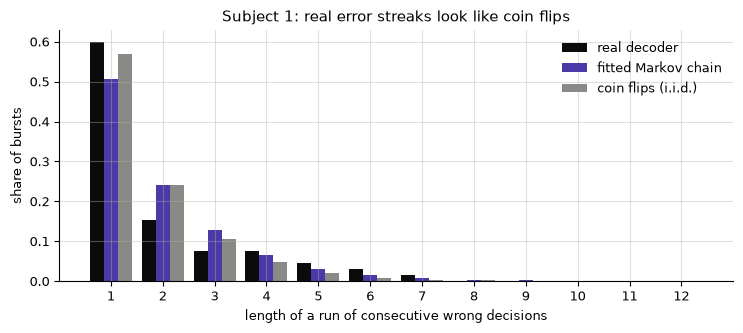

KS test p-value, real vs chain: 0.59; real vs coin flips: 0.68


In [8]:
def simulate_sequence(model, run_lengths, rng, *, iid=False):
    if iid:
        n = int(sum(run_lengths))
        return (rng.random(n) < model.marginal_error_rate).astype(int)
    p_rd, p_dd = model.p_rd_smoothed, model.p_dd_smoothed
    stationary = p_rd / (p_rd + (1.0 - p_dd)) if (p_rd + 1.0 - p_dd) > 0 else 0.0
    out = []
    for length in run_lengths:
        if length <= 0:
            continue
        state = int(rng.random() < stationary)   # a rest break has no memory
        seq = [state]
        for _ in range(length - 1):
            state = int(rng.random() < (p_dd if state else p_rd))
            seq.append(state)
        out.extend(seq)
    return np.asarray(out, dtype=int)


def burst_lengths(degraded, run=None):
    if run is None:
        run = np.zeros_like(degraded)
    lengths = []
    for r in np.unique(run):
        count = 0
        for v in degraded[run == r]:
            if v:
                count += 1
            elif count:
                lengths.append(count)
                count = 0
        if count:
            lengths.append(count)
    return np.asarray(lengths, dtype=int)


def validate_bursts(model, traces, rng, *, n_sequences=200, max_len=12):
    t = traces.for_subject(model.subject)
    run_lengths = [int((t.run == r).sum()) for r in np.unique(t.run)]
    empirical = burst_lengths((t.correct == 0).astype(int), t.run)
    syn_run = np.concatenate([np.full(n, i) for i, n in enumerate(run_lengths)])

    def pool(iid):
        return np.concatenate([burst_lengths(simulate_sequence(model, run_lengths, rng, iid=iid), syn_run)
                               for _ in range(n_sequences)])

    def hist(a):
        counts = np.bincount(np.clip(a, 1, max_len), minlength=max_len + 1)[1:]
        return counts / counts.sum()

    chain, iid = pool(False), pool(True)
    return {"empirical_hist": hist(empirical), "markov_hist": hist(chain), "iid_hist": hist(iid),
            "ks_markov_p": stats.ks_2samp(empirical, chain).pvalue,
            "ks_iid_p": stats.ks_2samp(empirical, iid).pvalue}


max_len = cfg["command_error.validation.burst_hist_max_len"]
check = validate_bursts(fits[1], tr, np.random.default_rng([SEED, 1]),
                        n_sequences=cfg["command_error.validation.n_synthetic_sequences"],
                        max_len=max_len)

L = np.arange(1, max_len + 1)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(L - 0.27, check["empirical_hist"], 0.27, color=INK, label="real decoder")
ax.bar(L, check["markov_hist"], 0.27, color=VIOLET, label="fitted Markov chain")
ax.bar(L + 0.27, check["iid_hist"], 0.27, color=GREY, label="coin flips (i.i.d.)")
ax.set(xlabel="length of a run of consecutive wrong decisions", ylabel="share of bursts",
       xticks=L, title="Subject 1: real error streaks look like coin flips")
ax.legend(frameon=False)
fig.tight_layout()
save_fig("01_s2_bursts_subject1")
print(f"KS test p-value, real vs chain: {check['ks_markov_p']:.2f}; real vs coin flips: {check['ks_iid_p']:.2f}")

### Result: no bursts in this dataset

**0 of 9 subjects** show significant streaks. The mean burst is 2.64 decisions against 2.56 for coin flips, less than a tenth of a decision apart. For most subjects $p_{dd} \approx p_{rd} \approx$ the error rate, which is exactly what memoryless means. The KS test (a standard test of whether two samples come from the same distribution) can't tell the real bursts from either model.

The test is not blind. During development a **positive control**: on synthetic data with real streaks built in, the same test fires at p < 0.0001.

**Why there are none: errors depend on *which class was cued*.**

In [9]:
error_by_class = 1 - traces.pivot_table(index="subject", columns="true_class_name",
                                        values="correct", aggfunc="mean")
error_by_class[list(CLASS_NAMES)].round(2)

true_class_name,left_hand,right_hand,feet,tongue
subject,,,,
1,0.56,0.31,0.85,0.07
2,0.82,0.51,0.04,0.40
3,0.57,0.08,0.40,0.18
4,0.88,0.43,0.35,0.79
5,0.94,0.82,0.56,0.92
6,0.53,0.97,0.54,0.44
7,0.86,0.81,0.68,0.07
8,0.83,0.50,0.33,0.35
9,0.83,0.79,0.86,0.17


Subject 1 is wrong on 85% of *feet* trials and on only 7% of *tongue* trials. Whether a decision is wrong is mostly set by **which class was cued**, and this dataset **randomises cue order** by design. So the errors are random too, and any slow drift in the person's state is swamped by the class effect.

That makes "no bursts" a property of this lab paradigm (cued, balanced, randomised), not proof that BCI errors never cluster. A self-paced BCI could well show streaks.

**What the project did about it.** It **kept the chain** (the right model *if* bursts exist) but turned burstiness from an assumption into a **dial** that Section 6 sweeps. `with_burst_length(B)` (in the class above) sets a target mean burst length $B$ while holding the subject's error rate $\pi$ fixed:

$$p_{dr} = \frac{1}{B}, \qquad p_{rd} = \frac{\pi\, p_{dr}}{1-\pi}, \qquad p_{dd} = 1 - p_{dr}$$

At $B = 1/(1-\pi)$ this is exactly coin flips. The dial is set as a **multiplier** of each subject's own coin-flip burst length (×1 means coin flips, ×4 means very streaky), because that length differs a lot between subjects: 1.45 for subject 3, 5.24 for subject 5.

The function **refuses** impossible values instead of clipping them. The first version used one absolute length for everyone; for subject 5, $p_{rd}$ went above 1 and was silently clipped, which changed the error rate being tested. That is **Defect C** in the project's repair log.

### 2.3 When it is wrong, which wrong command?

Each imagined movement maps to a wheelchair command, measured **relative to where the chair is facing** (the mapping from Part 1):

| imagined movement | command | direction |
|---|---|---|
| left hand | turn left | +90° |
| right hand | turn right | −90° |
| feet | forward | 0° |
| tongue | stop | none |

For a wrong decision, the channel needs to know *what* the decoder said instead. That comes from Part 1's confusion matrix with the diagonal (the correct answers) removed and each row rescaled to sum to 1. That gives, for each intended class, the distribution of wrong predictions. If a class were never wrong at all, its row falls back to uniform.

In [10]:
@dataclass
class ConfusionSampler:
    subject: int
    matrix: np.ndarray          # row = intended, P(which wrong class)
    class_names: tuple

    @classmethod
    def from_confusion(cls, subject, confusion, class_names):
        m = np.array(confusion, dtype=float)
        np.fill_diagonal(m, 0.0)
        totals = m.sum(axis=1, keepdims=True)
        n = m.shape[0]
        uniform = (1.0 - np.eye(n)) / (n - 1)   # if a row has no errors
        m = np.where(totals > 0, m / np.maximum(totals, 1e-12), uniform)
        return cls(subject=subject, matrix=m, class_names=class_names)

    def sample(self, true_class, rng):
        return int(rng.choice(len(self.class_names), p=self.matrix[true_class]))


def confusion_counts(traces, subject):
    t = traces.for_subject(subject)
    counts = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)
    np.add.at(counts, (t.true_class, t.pred_class), 1)
    return counts


wrong_given = ConfusionSampler.from_confusion(1, confusion_counts(tr, 1), CLASS_NAMES)
pd.DataFrame(wrong_given.matrix, index=CLASS_NAMES, columns=CLASS_NAMES).round(2)

,left_hand,right_hand,feet,tongue
left_hand,0.00,0.50,0.00,0.50
right_hand,0.55,0.00,0.27,0.18
feet,0.11,0.02,0.00,0.87
tongue,0.20,0.20,0.60,0.00


**Read a row as:** "the user meant *this* and the decoder got it wrong, so here is what it said instead." Subject 1's decoder is heavily biased toward *tongue*: when it gets a *feet* (forward) trial wrong, it says **stop** 87% of the time, which halts the chair.

### 2.4 How late?

Each decision's latency is drawn by **bootstrap**: pick one of that subject's real measured latencies at random, with replacement. A fitted curve wasn't used because the real distribution has two spikes. One is at 2.0 s, the earliest possible decision, when the first 2-second window is already confident. The other is at 4.0 s, for **censored** trials where the decoder never got confident. No simple curve fits that shape.

Draws are clipped to 0.1–3.0 s. Censored trials are only *lower bounds* on the true latency, so the simulated channel is, if anything, **faster** than the real decoder. Keeping them at the cap understates their latency; dropping them would understate it far more, because it would remove exactly the slow trials.

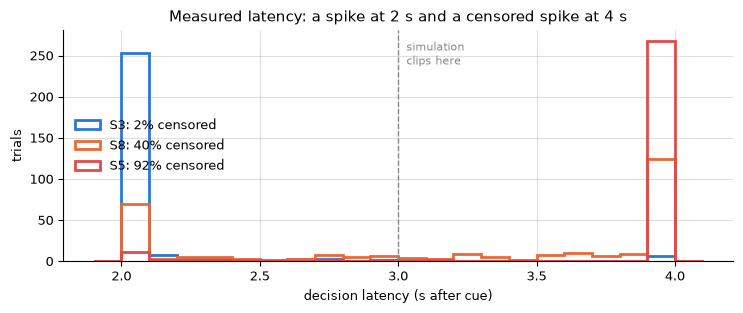

In [11]:
@dataclass
class LatencySampler:
    subject: int
    samples: np.ndarray
    censored: np.ndarray
    min_s: float
    max_s: float

    @property
    def censored_fraction(self):
        return float(self.censored.mean()) if self.censored.size else float("nan")

    def sample(self, rng, n=1):
        draws = rng.choice(self.samples, size=n, replace=True)
        return np.clip(draws, self.min_s, self.max_s)


lat_max = cfg["command_error.latency.max_s"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.arange(1.9, 4.2, 0.1)
for s, color in [(3, BLUE), (8, ORANGE), (5, RED)]:
    t = tr.for_subject(s)
    ax.hist(t.latency_s, bins=bins, histtype="step", lw=2, color=color,
            label=f"S{s}: {t.censored.mean():.0%} censored")
ax.axvline(lat_max, color=GREY, ls="--", lw=1)
ax.text(lat_max + 0.03, ax.get_ylim()[1] * 0.85, "simulation\nclips here", fontsize=8, color=GREY)
ax.set(xlabel="decision latency (s after cue)", ylabel="trials",
       title="Measured latency: a spike at 2 s and a censored spike at 4 s")
ax.legend(frameon=False)
fig.tight_layout()
save_fig("02_s2_latency")

### 2.5 How confident? (and a bug that was caught)

Each decision also carries a **confidence**: Part 1's calibrated probability. The channel draws it from that subject's real confidences, but from the **"correct" pile when the decision is correct** and the **"wrong" pile when it is wrong**.

That split matters. The first version drew from a single pile whatever the outcome, which made simulated confidence **useless by construction**: it said nothing about whether the command was right. Any conclusion like "confidence doesn't help" would then have been built in, not discovered. That is **Defect B** in the project's repair log.

How much does confidence really tell you? The standard measure is **AUC** (area under the ROC curve). Pick one correct trial and one wrong trial at random; AUC is the probability that the correct one has the higher confidence. 0.5 means confidence is useless; 1.0 means it separates them perfectly.

pooled AUC (all subjects together): 0.676
mean gap within a subject: 0.052


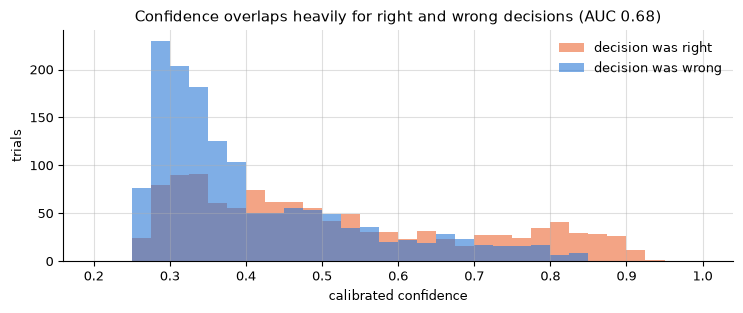

subject,1,2,3,4,5,6,7,8,9
when_wrong,0.555,0.442,0.595,0.306,0.336,0.348,0.540,0.420,0.310
when_right,0.563,0.574,0.687,0.321,0.329,0.365,0.643,0.496,0.344
gap,0.008,0.132,0.091,0.014,-0.007,0.017,0.103,0.077,0.034


In [12]:
def confidence_pools(df, subject):
    rows = df[df.subject == subject]   # file order kept
    pools = {"correct": rows.loc[rows.correct == 1, "p_calibrated"].to_numpy(dtype=float),
             "wrong": rows.loc[rows.correct == 0, "p_calibrated"].to_numpy(dtype=float)}
    for key, values in pools.items():
        if values.size == 0:
            raise ValueError(f"subject {subject} has no {key} trials")
    return pools


auc = roc_auc_score(traces.correct, traces.p_calibrated)
conf_gap = traces.groupby(["subject", "correct"]).p_calibrated.mean().unstack()
conf_gap.columns = ["when_wrong", "when_right"]
conf_gap["gap"] = conf_gap.when_right - conf_gap.when_wrong
print(f"pooled AUC (all subjects together): {auc:.3f}")
print(f"mean gap within a subject: {conf_gap.gap.mean():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.linspace(0.2, 1.0, 33)
ax.hist(traces.loc[traces.correct == 1, "p_calibrated"], bins=bins, alpha=0.6, color=ORANGE, label="decision was right")
ax.hist(traces.loc[traces.correct == 0, "p_calibrated"], bins=bins, alpha=0.6, color=BLUE, label="decision was wrong")
ax.set(xlabel="calibrated confidence", ylabel="trials",
       title=f"Confidence overlaps heavily for right and wrong decisions (AUC {auc:.2f})")
ax.legend(frameon=False)
fig.tight_layout()
save_fig("03_s2_confidence")
conf_gap.round(3).T

**Reading it.** Pooled over everyone, the AUC is about 0.68: better than useless, far from perfect. But the controller only ever sees **one subject at a time**, and within a subject the gap between "confidence when right" and "confidence when wrong" averages only about 0.05. For subject 5 it is **negative**: that decoder is slightly *more* confident when it is wrong. Much of the pooled 0.68 comes from the better subjects having both higher accuracy and higher confidence, which doesn't help within a single drive.

Keep this in mind: it is why confidence turns out to be nearly decorative in Section 6.

### 2.6 Putting it together: the command channel

The channel sits between the simulated user and the controller. Every 20 ms simulation step:

1. **Sample and hold.** Every `decision_interval_s` = 2 s, it takes one snapshot of the user's intent and holds it until the next decision. (*Zero-order hold* is the control name for holding a value constant between samples.)
2. **Delay.** Each decision arrives after a latency drawn from the subject's real latencies. Latencies are often longer than 2 s, so decisions overlap; the channel shows whichever decision has arrived most recently, as a real display would.
3. **Corrupt.** It advances the Markov chain. If this decision is degraded, it finds which of the four commands the user's intended direction is closest to, draws a wrong command from the confusion row (2.3), and **rotates** the intent by the angle between the two commands. The speed is kept, except for *stop*, which zeroes it. So the *geometry* of the errors comes from real data, not from an invented rule.
4. **Attach a confidence** from the matching pile (2.5). Under the `perfect_confidence` ablation it reports 1.0 or 0.0 instead, but it **still draws the random index**, so both conditions use the random-number stream identically and stay paired. (The first version skipped the draw and broke the pairing.)

Before the first decision arrives, the chair receives **no command at all**, and the confidence sits at the 0.25 prior (a uniform guess over 4 classes).

At the start of each drive, the chain's state is drawn from its long-run distribution, so a drive doesn't always begin "reliable".

In [13]:
# command directions, relative to the chair's heading
ARCHETYPE_ANGLES = {"left_hand": +np.pi / 2, "right_hand": -np.pi / 2,
                    "feet": 0.0, "tongue": np.nan}       # tongue = stop


@dataclass
class ChannelOutput:
    intent: np.ndarray
    confidence: float
    degraded: bool
    age_s: float
    n_decisions: int


@dataclass
class CommandChannel:
    error_model: MarkovErrorModel
    latency: LatencySampler
    confusion: ConfusionSampler
    confidences: dict
    decision_interval_s: float = 2.0
    prior: float = 0.25
    age_decay: bool = False
    decay_tau_s: float = 1.5
    oracle_confidence: bool = False
    _t: float = field(default=0.0, repr=False)
    _next_decision_t: float = field(default=0.0, repr=False)
    _pending: list = field(default_factory=list, repr=False)
    _active: dict = field(default=None, repr=False)
    _state_degraded: bool = field(default=False, repr=False)
    _n: int = field(default=0, repr=False)

    @classmethod
    def from_config(cls, cfg, error_model, latency, confusion, confidences):
        return cls(
            error_model=error_model, latency=latency, confusion=confusion,
            confidences={k: np.asarray(v, dtype=float) for k, v in confidences.items()},
            decision_interval_s=float(cfg["operator.decision_interval_s"]),
            prior=float(cfg["confidence.prior"]),
            age_decay=bool(cfg["confidence.age_decay.enabled"]),
            decay_tau_s=float(cfg["confidence.age_decay.tau_s"]),
            oracle_confidence=bool(cfg["decoder.oracle_confidence"]))

    def reset(self, rng):
        self._t = 0.0
        self._next_decision_t = 0.0
        self._pending = []
        self._active = None
        self._n = 0
        pi = self.error_model.stationary_error_rate      # start in long-run mix
        self._state_degraded = bool(rng.random() < (pi if np.isfinite(pi) else 0.0))

    def _advance_chain(self, rng, iid):
        if iid:
            self._state_degraded = bool(rng.random() < self.error_model.marginal_error_rate)
        else:
            p = (self.error_model.p_dd_smoothed if self._state_degraded
                 else self.error_model.p_rd_smoothed)
            self._state_degraded = bool(rng.random() < p)
        return self._state_degraded

    def _corrupt(self, intent, heading, rng):
        classes = list(self.confusion.class_names)
        if float(np.hypot(intent[0], intent[1])) < 1e-9:
            return intent.copy()
        # nearest command, body-relative
        rel = float(np.arctan2(intent[1], intent[0]) - heading)
        rel = (rel + np.pi) % (2 * np.pi) - np.pi
        angles = np.array([ARCHETYPE_ANGLES[c] for c in classes])
        finite = np.isfinite(angles)
        diffs = np.full(len(classes), np.inf)
        diffs[finite] = np.abs((angles[finite] - rel + np.pi) % (2 * np.pi) - np.pi)
        intended = int(np.argmin(diffs))

        received = self.confusion.sample(intended, rng)
        if not np.isfinite(ARCHETYPE_ANGLES[classes[received]]):
            return np.zeros(2)                            # decoded 'stop'
        rotation = float(ARCHETYPE_ANGLES[classes[received]] - ARCHETYPE_ANGLES[classes[intended]])
        c, s = np.cos(rotation), np.sin(rotation)
        return np.array([c * intent[0] - s * intent[1], s * intent[0] + c * intent[1]])

    def step(self, intent, heading, dt, rng, *, iid=False):
        if self._t >= self._next_decision_t:              # new decision
            degraded = self._advance_chain(rng, iid)
            emitted = (self._corrupt(intent, heading, rng) if degraded
                       else np.asarray(intent, dtype=float).copy())
            pool = self.confidences["wrong" if degraded else "correct"]
            idx = int(rng.integers(len(pool)))            # always drawn: keeps pairing
            conf = ((0.0 if degraded else 1.0) if self.oracle_confidence else float(pool[idx]))
            latency = float(self.latency.sample(rng, 1)[0])
            self._pending.append({"arrive": self._t + latency, "issued": self._t,
                                  "intent": emitted, "confidence": conf, "degraded": degraded})
            self._n += 1
            self._next_decision_t = self._t + self.decision_interval_s

        arrived = [d for d in self._pending if d["arrive"] <= self._t]
        if arrived:                                       # newest wins
            self._active = max(arrived, key=lambda d: d["issued"])
            self._pending = [d for d in self._pending if d["arrive"] > self._t]

        self._t += dt
        if self._active is None:                          # nothing arrived yet
            return ChannelOutput(np.zeros(2), self.prior, False, 0.0, self._n)

        age = self._t - self._active["issued"]
        conf = float(self._active["confidence"])
        if self.age_decay and not self.oracle_confidence:
            conf = self.prior + (conf - self.prior) * float(np.exp(-age / self.decay_tau_s))
        return ChannelOutput(intent=np.asarray(self._active["intent"], dtype=float),
                             confidence=float(np.clip(conf, 0.0, 1.0)),
                             degraded=bool(self._active["degraded"]),
                             age_s=float(age), n_decisions=self._n)

One bundle per subject: the fitted chain, the latency sampler, the confusion sampler, and the two confidence piles. Everything is built from the trial file, in file order.

In [14]:
def build_subject_models(cfg, traces_df, traces_arr):
    out = {}
    for s in traces_arr.subjects:
        t = traces_arr.for_subject(s)
        out[s] = {
            "markov": fit_markov(traces_arr, s, smoothing=cfg["command_error.fit.smoothing"]),
            "latency": LatencySampler(subject=s, samples=t.latency_s, censored=t.censored,
                                      min_s=float(cfg["command_error.latency.min_s"]),
                                      max_s=float(cfg["command_error.latency.max_s"])),
            "confusion": ConfusionSampler.from_confusion(s, confusion_counts(traces_arr, s), CLASS_NAMES),
            "confidences": confidence_pools(traces_df, s),
        }
    return out


MODELS = build_subject_models(cfg, traces, tr)


def channel_for(subject, cfg_=cfg):
    m = MODELS[subject]
    return CommandChannel.from_config(cfg_, m["markov"], m["latency"], m["confusion"], m["confidences"])


print({s: round(m["markov"].p_dd_smoothed, 3) for s, m in MODELS.items()})

{1: 0.504, 2: 0.42, 3: 0.39, 4: 0.64, 5: 0.82, 6: 0.615, 7: 0.579, 8: 0.489, 9: 0.675}


**Watching the channel.** Here the user wants to go **straight ahead** the whole time, and the chair faces straight ahead. A perfect channel would draw a flat line at "forward". Here is what subject 3 (best decoder) and subject 5 (worst) actually deliver over 40 seconds.

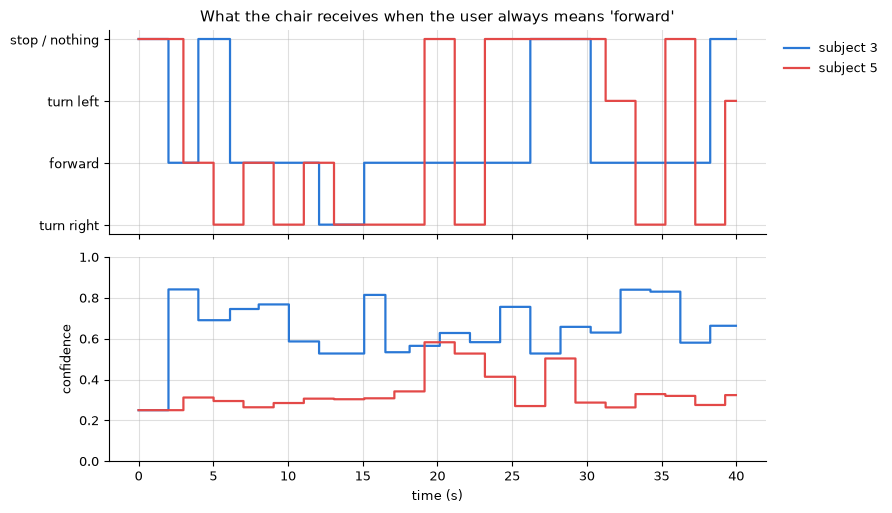

subject 3: the command in use is on average 2.95 s old
subject 5: the command in use is on average 3.72 s old


In [15]:
intent = np.array([1.0, 0.0])   # always "forward"
STOP_Y = 180                     # where stop is drawn

fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
command_age = {}
for s, color in [(3, BLUE), (5, RED)]:
    ch = channel_for(s)
    rng = np.random.default_rng([SEED, s, 7])
    ch.reset(rng)
    t, angle, conf, ages = [], [], [], []
    for k in range(int(40 / dt)):
        out = ch.step(intent, heading=0.0, dt=dt, rng=rng)
        t.append(k * dt)
        stopped = np.hypot(*out.intent) < 1e-9
        angle.append(STOP_Y if stopped else np.degrees(np.arctan2(out.intent[1], out.intent[0])))
        conf.append(out.confidence)
        ages.append(out.age_s)
    command_age[s] = np.mean(ages)
    axes[0].step(t, angle, where="post", color=color, lw=1.6, label=f"subject {s}")
    axes[1].step(t, conf, where="post", color=color, lw=1.6)

axes[0].set(yticks=[-90, 0, 90, STOP_Y], yticklabels=["turn right", "forward", "turn left", "stop / nothing"],
            title="What the chair receives when the user always means 'forward'")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].set(xlabel="time (s)", ylabel="confidence", ylim=(0, 1))
fig.tight_layout()
save_fig("04_s2_channel")
for s, a in command_age.items():
    print(f"subject {s}: the command in use is on average {a:.2f} s old")

**Reading it.** Nothing arrives for the first couple of seconds. After that, subject 3 mostly delivers "forward", with occasional wrong turns or stops, while subject 5 mostly delivers the wrong thing. The command only changes every ~2 s, and the confidence jumps with it.

The **command age** printed above matters in Section 7: the command the chair acts on is typically 3–4 seconds old, because of the 2 s hold plus the latency.

---
## 3. The plants: what is being controlled

In control theory, the thing being controlled is called the **plant**. The project uses two plants, for two different jobs.

**Plant A, the double integrator**, is a point mass you can push in x and in y independently: push, and it accelerates. It has **no heading**, so "turn left" means nothing to it. It is not a realistic wheelchair. It exists because its maths can be solved *exactly*, which is what the stability analysis in Section 7 needs.

**Plant B, the unicycle**, is the wheelchair. It has a heading. It **cannot move sideways**: to reach a point on its left it must turn first, then drive. A constraint like that, on *how* you can move rather than *where* you can be, is called **nonholonomic**. Its motors also **lag**: ask for 1 m/s and the speed gets there gradually, not instantly.

All the wheelchair experiments in Section 6 use Plant B.

### 3.1 Plant B, the wheelchair

The state is position $(x, y)$, heading $\theta$, forward speed $v$ and turn rate $\omega$. The two inputs are a **speed command** $v_{cmd}$ and a **turn-rate command** $\omega_{cmd}$. Each motor is a **first-order lag**: the actual speed chases the commanded speed and closes about 63% of the gap every time constant ($\tau_v$ = 0.30 s for speed, $\tau_w$ = 0.20 s for turning). On top of that there are speed limits and acceleration limits:

$$\dot x = v\cos\theta, \qquad \dot y = v\sin\theta, \qquad \dot\theta = \omega$$

$$\dot v = \operatorname{clip}\!\Big(\frac{v_{cmd}-v}{\tau_v},\, \pm\dot v_{max}\Big), \qquad \dot\omega = \operatorname{clip}\!\Big(\frac{\omega_{cmd}-\omega}{\tau_w},\, \pm\dot\omega_{max}\Big)$$

The code steps this with **RK4**, the classic 4th-order Runge–Kutta method, a standard accurate way to step an ODE forward in time. Afterwards it wraps the heading into $(-\pi, \pi]$ and clips the speeds to their limits.

**From "where I want to go" to motor commands.** The user (Section 4) and the channel (Section 2) speak in **intent vectors**: an arrow in the room meaning "go that way, this hard". `command_from_intent` converts the arrow:

$$\omega_{cmd} = k_{heading}\, e_\theta, \qquad v_{cmd} = \min(|\text{intent}|, v_{max})\, \big(\max(\cos e_\theta, 0)\big)^{2}$$

where $e_\theta$ is the angle between the arrow and the chair's heading. The squared cosine is a **speed gate**: a chair facing 90° away from where it should go doesn't drift sideways, it **stops and turns**. That is the nonholonomic constraint showing up in the controller.

(The original simulator's unicycle also has simulated range sensors. The experiments never use them, so they are left out here.)

In [16]:
def wrap_angle(a):
    return (np.asarray(a) + np.pi) % (2.0 * np.pi) - np.pi


@dataclass
class Unicycle:
    tau_v: float = 0.30
    tau_w: float = 0.20
    v_max: float = 1.2
    v_min: float = -0.4
    w_max: float = 1.5
    dv_max: float = 1.0
    dw_max: float = 3.0
    collision_radius: float = 0.35
    k_heading: float = 2.0
    speed_gate_power: float = 2.0

    @classmethod
    def from_config(cls, cfg):
        sec = cfg.section("plants.unicycle")
        return cls(tau_v=float(sec["tau_v"]), tau_w=float(sec["tau_w"]),
                   v_max=float(sec["v_max"]), v_min=float(sec["v_min"]),
                   w_max=float(sec["w_max"]), dv_max=float(sec["dv_max"]),
                   dw_max=float(sec["dw_max"]),
                   collision_radius=float(sec["collision_radius"]),
                   k_heading=float(sec["k_heading"]),
                   speed_gate_power=float(sec["speed_gate_power"]))

    def reset(self, pose=(0.0, 0.0, 0.0), v=0.0, omega=0.0):
        return np.array([pose[0], pose[1], pose[2], v, omega], dtype=float)

    def saturate(self, u):
        u = np.asarray(u, dtype=float)
        return np.array([float(np.clip(u[0], self.v_min, self.v_max)),
                         float(np.clip(u[1], -self.w_max, self.w_max))])

    def derivative(self, state, u):
        _, _, theta, v, omega = state
        dv = np.clip((u[0] - v) / self.tau_v, -self.dv_max, self.dv_max)
        dw = np.clip((u[1] - omega) / self.tau_w, -self.dw_max, self.dw_max)
        return np.array([v * np.cos(theta), v * np.sin(theta), omega, dv, dw])

    def step(self, state, u, dt):
        s = np.asarray(state, dtype=float)
        u = self.saturate(u)
        k1 = self.derivative(s, u)                    # RK4
        k2 = self.derivative(s + 0.5 * dt * k1, u)
        k3 = self.derivative(s + 0.5 * dt * k2, u)
        k4 = self.derivative(s + dt * k3, u)
        out = s + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        out[2] = wrap_angle(out[2])
        out[3] = np.clip(out[3], self.v_min, self.v_max)
        out[4] = np.clip(out[4], -self.w_max, self.w_max)
        return out

    def world_velocity(self, state):
        s = np.asarray(state, dtype=float)
        return s[3] * np.array([np.cos(s[2]), np.sin(s[2])])

    def is_collision(self, state, grid):
        return bool(grid.is_collision(np.asarray(state, dtype=float)[:2], self.collision_radius))

    def command_from_intent(self, state, intent):
        s = np.asarray(state, dtype=float)
        intent = np.asarray(intent, dtype=float)
        speed = float(np.hypot(intent[0], intent[1]))
        if speed < 1e-9:
            return np.zeros(2)
        heading_error = float(wrap_angle(np.arctan2(intent[1], intent[0]) - s[2]))
        gate = max(np.cos(heading_error), 0.0) ** self.speed_gate_power   # turn first
        return self.saturate(np.array([min(speed, self.v_max) * gate,
                                       self.k_heading * heading_error]))


uni = Unicycle.from_config(cfg)
uni

Unicycle(tau_v=0.3, tau_w=0.2, v_max=1.2, v_min=-0.4, w_max=1.5, dv_max=1.0, dw_max=3.0, collision_radius=0.35, k_heading=2.0, speed_gate_power=2.0)

**The lag in action.** Starting from rest, ask for 1.0 m/s and 0.5 rad/s at the same time.

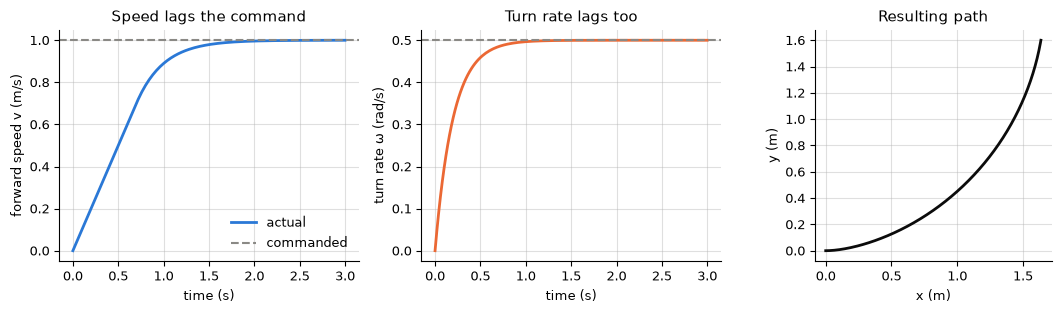

,v_cmd (m/s),w_cmd (rad/s)
intent angle from heading (deg),,
0,1.00,0.000
30,0.75,1.047
60,0.25,1.500
90,0.00,1.500
135,0.00,1.500


In [17]:
command = np.array([1.0, 0.5])   # v_cmd, w_cmd
state = uni.reset(pose=(0.0, 0.0, 0.0))
log = [state]
for _ in range(int(3 / dt)):
    state = uni.step(state, command, dt)
    log.append(state)
log = np.array(log)
t = np.arange(len(log)) * dt

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].plot(t, log[:, 3], color=BLUE, lw=2, label="actual")
axes[0].axhline(command[0], color=GREY, ls="--", label="commanded")
axes[0].set(xlabel="time (s)", ylabel="forward speed v (m/s)", title="Speed lags the command")
axes[0].legend(frameon=False)
axes[1].plot(t, log[:, 4], color=ORANGE, lw=2)
axes[1].axhline(command[1], color=GREY, ls="--")
axes[1].set(xlabel="time (s)", ylabel="turn rate ω (rad/s)", title="Turn rate lags too")
axes[2].plot(log[:, 0], log[:, 1], color=INK, lw=2)
axes[2].set(xlabel="x (m)", ylabel="y (m)", title="Resulting path", aspect="equal")
fig.tight_layout()
save_fig("05_s3_unicycle_lag")

rows = []
for deg in [0, 30, 60, 90, 135]:
    arrow = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    v_cmd, w_cmd = uni.command_from_intent(uni.reset(), arrow)
    rows.append({"intent angle from heading (deg)": deg, "v_cmd (m/s)": round(v_cmd, 3),
                 "w_cmd (rad/s)": round(w_cmd, 3)})
pd.DataFrame(rows).set_index("intent angle from heading (deg)")

The speed doesn't jump to 1 m/s; it rises over about a second, because the acceleration limit (1 m/s²) bites before the lag does. The path curves left because the chair turns while it speeds up.

The table shows the speed gate. At 0° the chair drives straight at full requested speed. At 60° the speed is already cut to a quarter ($\cos^2 60° = 0.25$). At 90° and beyond it only turns, and the turn rate saturates at its 1.5 rad/s limit.

### 3.2 Plant A, the point mass

One axis of the point mass is $\dot p = v,\ \dot v = u - d\,v$. Because it is linear, it can be stepped **exactly** over one time step $h$ with the matrix exponential of the augmented system: no RK4 error at all. `zoh_axis_coefficients` returns the four numbers that step needs ("ZOH" again because the input is held constant over the step).

Its autopilot is an **LQR** controller (linear-quadratic regulator): the feedback $u = -K_1 p - K_2 v$ that minimises a weighted sum of position error, velocity and control effort, $\int (q_p p^2 + q_v v^2 + r u^2)\, dt$. For this plant the gains have a closed form:

$$K_1 = \sqrt{q_p / r}, \qquad K_2 = -d + \sqrt{d^2 + \frac{q_v + 2\sqrt{r\,q_p}}{r}}$$

`lqr_axis_gains` computes them and also **checks** them against a numerical solve of the algebraic Riccati equation (`solve_continuous_are`), raising an error if the two disagree. That's a good habit: whenever there is a closed form, also check it numerically.

In [18]:
def zoh_axis_coefficients(d, h):
    a = np.array([[0.0, 1.0], [0.0, -d]])
    b = np.array([[0.0], [1.0]])
    m = np.zeros((3, 3))
    m[:2, :2] = a
    m[:2, 2:3] = b
    em = expm(m * h)
    return float(em[0, 1]), float(em[0, 2]), float(em[1, 1]), float(em[1, 2])


def lqr_axis_gains(d, q_p, q_v, r, *, check=True):
    k1 = float(np.sqrt(q_p / r))
    k2 = float(-d + np.sqrt(d**2 + (q_v + 2.0 * np.sqrt(r * q_p)) / r))
    if check:   # closed form vs Riccati
        a = np.array([[0.0, 1.0], [0.0, -d]])
        b = np.array([[0.0], [1.0]])
        p = solve_continuous_are(a, b, np.diag([q_p, q_v]), np.array([[r]]))
        k_num = np.linalg.solve(np.array([[r]]), b.T @ p)
        if not np.allclose([k1, k2], [k_num[0, 0], k_num[0, 1]], atol=1e-9):
            raise AssertionError(f"closed-form LQR {(k1, k2)} disagrees with CARE {tuple(k_num[0])}")
    return k1, k2


@dataclass
class DoubleIntegrator:
    damping: float = 1.0
    u_max: float = 6.0
    workspace_radius: float = 2.0

    @classmethod
    def from_config(cls, cfg):
        sec = cfg.section("plants.double_integrator")
        return cls(damping=float(sec["damping"]), u_max=float(sec["u_max"]),
                   workspace_radius=float(sec["workspace_radius"]))

    def reset(self, position=(0.0, 0.0), velocity=(0.0, 0.0)):
        return np.array([*position, *velocity], dtype=float)

    def saturate(self, u):
        return np.clip(np.asarray(u, dtype=float), -self.u_max, self.u_max)

    def step(self, state, u, dt):
        c1, c2, c3, c4 = zoh_axis_coefficients(self.damping, dt)   # exact step
        s = np.asarray(state, dtype=float)
        p, v = s[:2], s[2:]
        u = self.saturate(u)
        return np.concatenate([p + c1 * v + c2 * u, c3 * v + c4 * u])

    def command_from_intent(self, state, intent):
        return self.saturate(intent)


lqr = cfg.section("control.lqr")
K1, K2 = lqr_axis_gains(cfg["plants.double_integrator.damping"],
                        lqr["q_position"], lqr["q_velocity"], lqr["r_effort"])
print(f"LQR gains K1 = {K1:.6f}, K2 = {K2:.6f} (closed form agrees with the Riccati solve)")

LQR gains K1 = 3.162278, K2 = 1.885231 (closed form agrees with the Riccati solve)


### 3.3 The three rooms

The rooms are **occupancy grids**: the floor is split into 5 cm cells, each either free or blocked. Once per room, the code computes for every free cell its **distance to the nearest obstacle**, the *clearance*, using a **Euclidean distance transform** (`scipy.ndimage.distance_transform_edt`). After that every collision check is a table look-up: the chair, a disc of radius 0.35 m, has collided when the clearance at its centre is ≤ 0.35 m.

Each room also gets a **navigation field**: the shortest-path distance from every cell to the goal *through free space*, found with **Dijkstra's algorithm** on the grid (8 neighbours; diagonal steps cost √2 cells). Cells too close to an obstacle for the chair's centre are treated as blocked. The autopilot uses this field in Section 5, and why it needs it is a bug story told there.

In [19]:
@dataclass
class OccupancyGrid:
    occupied: np.ndarray        # (ny, nx) bool
    clearance_m: np.ndarray     # distance to nearest obstacle
    resolution: float
    origin: np.ndarray
    bounds: tuple
    name: str
    start: tuple                # (x, y, theta)
    goal: tuple                 # (x, y)
    _nav_cache: dict = field(default_factory=dict, repr=False)

    def world_to_index(self, xy):
        rel = (np.asarray(xy, dtype=float) - self.origin) / self.resolution
        return np.floor(rel[..., 0]).astype(int), np.floor(rel[..., 1]).astype(int)

    def in_bounds(self, ix, iy):
        ny, nx = self.occupied.shape
        return (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)

    def clearance(self, xy):
        ix, iy = self.world_to_index(xy)
        ok = self.in_bounds(ix, iy)
        out = np.zeros(ix.shape, dtype=float)       # outside = no room
        if np.any(ok):
            out[ok] = self.clearance_m[iy[ok], ix[ok]]
        return out

    def is_collision(self, xy, radius):
        return self.clearance(xy) <= radius

    def navigation(self, goal, radius):
        key = (round(float(goal[0]), 6), round(float(goal[1]), 6), round(float(radius), 6))
        if key not in self._nav_cache:               # compute once
            self._nav_cache[key] = navigation_field(self, np.asarray(goal, float), radius)
        return self._nav_cache[key]


def build_environment(cfg, name):
    env = cfg.section("environments")[name]
    res = float(cfg["defaults.resolution"])
    x0, y0, x1, y1 = (float(v) for v in env["bounds"])
    nx, ny = int(np.ceil((x1 - x0) / res)), int(np.ceil((y1 - y0) / res))
    occupied = np.zeros((ny, nx), dtype=bool)
    for ox0, oy0, ox1, oy1 in env["obstacles"]:
        i0 = max(int(np.floor((ox0 - x0) / res)), 0)
        j0 = max(int(np.floor((oy0 - y0) / res)), 0)
        i1 = min(int(np.ceil((ox1 - x0) / res)), nx)
        j1 = min(int(np.ceil((oy1 - y0) / res)), ny)
        if i1 > i0 and j1 > j0:
            occupied[j0:j1, i0:i1] = True
    clearance_m = ndimage.distance_transform_edt(~occupied) * res   # once per room
    return OccupancyGrid(
        occupied=occupied, clearance_m=clearance_m.astype(float), resolution=res,
        origin=np.array([x0, y0], dtype=float), bounds=(x0, y0, x1, y1), name=name,
        start=(float(env["start"]["x"]), float(env["start"]["y"]), float(env["start"].get("theta", 0.0))),
        goal=(float(env["goal"]["x"]), float(env["goal"]["y"])))


def navigation_field(grid, goal, radius):
    free = grid.clearance_m > radius
    ny, nx = grid.occupied.shape
    dist = np.full((ny, nx), np.inf)
    gx, gy = grid.world_to_index(np.asarray(goal, dtype=float))
    gx, gy = int(gx), int(gy)
    if not (0 <= gx < nx and 0 <= gy < ny):
        return dist
    if not free[gy, gx]:                              # goal too close to a wall
        ys, xs = np.nonzero(free)
        if ys.size == 0:
            return dist
        k = int(np.argmin((ys - gy) ** 2 + (xs - gx) ** 2))
        gy, gx = int(ys[k]), int(xs[k])
    res = grid.resolution
    diag = res * float(np.sqrt(2.0))
    neighbours = [(-1, 0, res), (1, 0, res), (0, -1, res), (0, 1, res),
                  (-1, -1, diag), (-1, 1, diag), (1, -1, diag), (1, 1, diag)]
    dist[gy, gx] = 0.0
    heap = [(0.0, gy, gx)]
    while heap:                                       # Dijkstra
        d, y, x = heapq.heappop(heap)
        if d > dist[y, x]:
            continue
        for dy, dx, step in neighbours:
            ny_, nx_ = y + dy, x + dx
            if not (0 <= ny_ < ny and 0 <= nx_ < nx) or not free[ny_, nx_]:
                continue
            nd = d + step
            if nd < dist[ny_, nx_]:
                dist[ny_, nx_] = nd
                heapq.heappush(heap, (nd, ny_, nx_))
    return dist


def sample_field(grid, field_, xy):
    ix, iy = grid.world_to_index(xy)
    ok = grid.in_bounds(ix, iy)
    out = np.full(ix.shape, np.inf)
    if np.any(ok):
        out[ok] = field_[iy[ok], ix[ok]]
    return out


ROOMS = list(cfg["experiment.environments"])
GRIDS = {name: build_environment(cfg, name) for name in ROOMS}
{name: g.occupied.shape for name, g in GRIDS.items()}

{'corridor': (80, 240), 'doorway': (160, 200), 'cluttered': (200, 240)}

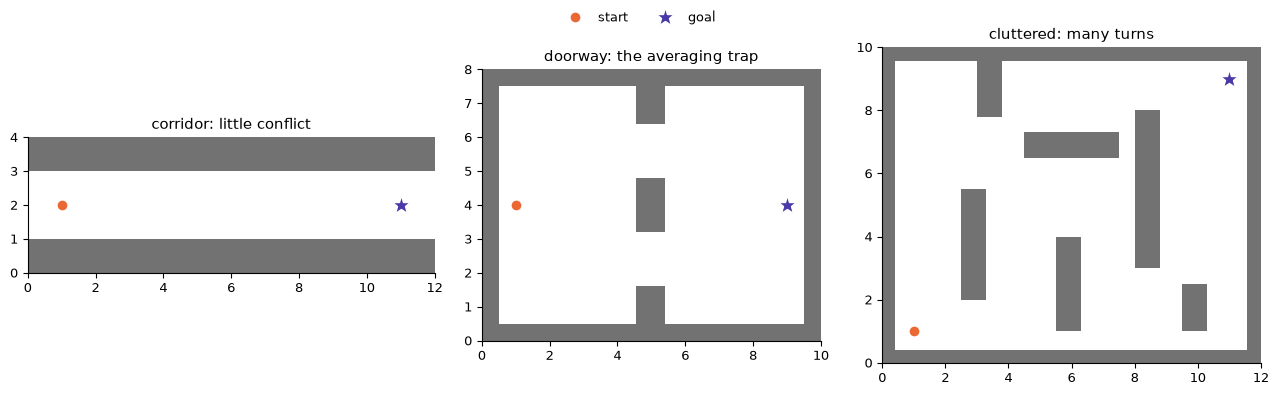

In [20]:
def draw_room(ax, grid, title=None):
    x0, y0, x1, y1 = grid.bounds
    ax.imshow(grid.occupied, origin="lower", extent=(x0, x1, y0, y1),
              cmap="Greys", vmin=0, vmax=1.6, interpolation="nearest")
    ax.plot(*grid.start[:2], "o", color=ORANGE, ms=8, mec="white")
    ax.plot(*grid.goal, "*", color=VIOLET, ms=14, mec="white")
    ax.set(aspect="equal", title=title or grid.name)
    ax.grid(False)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [12, 10, 12]})
notes = {"corridor": "corridor: little conflict", "doorway": "doorway: the averaging trap",
         "cluttered": "cluttered: many turns"}
for ax, name in zip(axes, ROOMS):
    draw_room(ax, GRIDS[name], notes[name])
fig.legend(axes[0].lines, ["start", "goal"], frameon=False, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig("06_s3_rooms")

- **Corridor:** a straight corridor 2 m wide. The user and the autopilot mostly agree here, so this room isolates the cost of a noisy, late decoder.
- **Doorway:** a pillar in the middle with a gap on each side. It is built so that going left is safe, going right is safe, and **the average of the two points straight at the pillar**. Section 5 shows that trap in action.
- **Cluttered:** an open room with scattered obstacles and several direction changes, so the danger level changes all the time.

---
## 4. The simulated user

### The problem

Recorded EEG cannot react to what the wheelchair does, but a real user would: they see the chair drift and correct it. So the closed loop needs a **model of the user**.

### The model, in words

The user is a competent but **slow-to-react** driver. They look at where the chair **was 0.2 s ago** (seeing, deciding and acting all take time) and ask for motion **toward the goal, harder when further away** (the proportional, P, part), **minus a bit for the speed already built up**, so they don't overshoot (the derivative, D, part). That is a **PD controller** with a **delay** in front of it:

$$\text{intent}(t) = K_p\,\big(\text{goal} - p(t-\tau_h)\big) - K_d\, v(t-\tau_h), \qquad K_p = 4,\ K_d = 2,\ \tau_h = 0.2\text{ s}$$

The user **always knows the goal** and **never changes its mind**; the decoding errors all live in the channel (Section 2). Two limits shape every result after this:

- **It doesn't steer around obstacles.** Its arrow always points straight at the goal, which in the doorway means straight through the pillar. So even a *perfect* decoder would crash a user-alone chair there; Section 6 checks this directly.
- **It never adapts.** Real users learn their decoder and change strategy; this one never does. This is the project's biggest gap.

### The delay buffer, and why it is easy to get wrong

The 0.2 s delay is 10 steps of 20 ms. The code keeps the last 10 states in a **ring buffer** (a fixed-size list that wraps around) and, every step, **reads the oldest slot before overwriting it**.

The order matters. The two obvious alternatives, reading *after* writing or using a 10-long `deque`, give a delay of 9 steps, or even **zero** before the buffer fills. Nothing crashes and nothing looks wrong in a plot, but the very delay this project studies silently disappears.

The code also **refuses** a delay that isn't a whole number of steps, instead of rounding it quietly.

In [21]:
class TransportDelay:
    def __init__(self, delay_steps, initial):
        if delay_steps < 0:
            raise ValueError(f"delay_steps must be >= 0, got {delay_steps}")
        self.delay_steps = int(delay_steps)
        initial = np.asarray(initial, dtype=float)
        self._buf = [initial.copy() for _ in range(max(self.delay_steps, 1))]
        self._k = 0

    def reset(self, initial):
        initial = np.asarray(initial, dtype=float)
        for i in range(len(self._buf)):
            self._buf[i] = initial.copy()
        self._k = 0

    def push(self, value):
        value = np.asarray(value, dtype=float)
        if self.delay_steps == 0:
            self._k += 1
            return value.copy()
        idx = self._k % self.delay_steps
        out = self._buf[idx]            # read first: written n steps ago
        self._buf[idx] = value.copy()   # then overwrite
        self._k += 1
        return out


@dataclass
class DelayedPDOperator:
    kp: float = 4.0
    kd: float = 2.0
    tau_h: float = 0.20
    goal: np.ndarray = field(default_factory=lambda: np.zeros(2))
    _delay: TransportDelay = field(default=None, repr=False)
    _dt: float = field(default=0.0, repr=False)
    _last_perceived: np.ndarray = field(default=None, repr=False)

    @classmethod
    def from_config(cls, cfg, goal):
        sec = cfg.section("operator")
        return cls(kp=float(sec["kp"]), kd=float(sec["kd"]), tau_h=float(sec["tau_h"]),
                   goal=np.asarray(goal, dtype=float))

    def delay_steps(self, dt):
        n = int(round(self.tau_h / dt))
        if abs(n * dt - self.tau_h) > 1e-9:         # refuse, don't round
            raise ValueError(f"tau_h={self.tau_h} is not a whole multiple of dt={dt}")
        return n

    def reset(self, dt, position, velocity):
        self._dt = float(dt)
        initial = np.concatenate([np.asarray(position, float), np.asarray(velocity, float)])
        self._last_perceived = None
        n = self.delay_steps(dt)
        if self._delay is None or self._delay.delay_steps != n:
            self._delay = TransportDelay(n, initial)
        else:
            self._delay.reset(initial)

    def intent(self, position, velocity):
        if self._delay is None:
            raise RuntimeError("call reset() before intent()")
        delayed = self._delay.push(np.concatenate([np.asarray(position, float),
                                                   np.asarray(velocity, float)]))
        self._last_perceived = delayed
        p_del, v_del = delayed[:2], delayed[2:]
        return self.kp * (self.goal - p_del) - self.kd * v_del

    def perceived_state(self):
        if self._last_perceived is None:
            raise RuntimeError("call intent() before perceived_state()")
        return self._last_perceived.copy()


# ramp test: push 0, 1, 2, ... and check each value comes out exactly n steps later
n = round(cfg["operator.tau_h"] / dt)
buffer = TransportDelay(n, initial=np.array([0.0]))
pushed = np.arange(15.0)
came_out = [buffer.push(np.array([k]))[0] for k in pushed]
assert came_out[n:] == list(pushed[:-n])          # exactly n steps late
pd.DataFrame({"pushed at step k": pushed.astype(int),
              "returned": came_out}).set_index("pushed at step k").T

pushed at step k,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
returned,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.0,4.0


For the first 10 steps the buffer returns its starting value (0, standing for "the history before the drive began"). From step 10 on, step $k$ returns $k - 10$: **exactly 10 steps of delay**, and the `assert` would fail if it weren't.

**Does the model user actually drive well?** With a perfect channel (no decoder at all) and the point mass, the delayed PD user should reach a goal 1 m away smoothly:

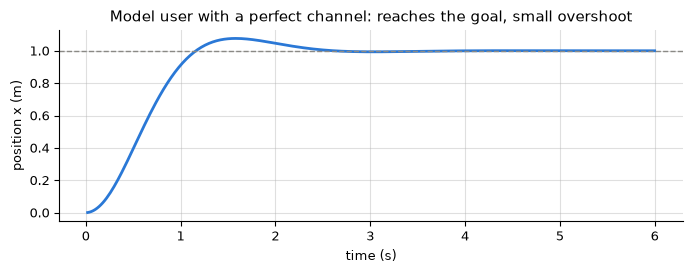

final position 1.000 m, peak 1.076 m


In [22]:
point_mass = DoubleIntegrator.from_config(cfg)
human = DelayedPDOperator.from_config(cfg, goal=np.array([1.0, 0.0]))
state = point_mass.reset(position=(0.0, 0.0))
human.reset(dt, state[:2], state[2:])
xs = []
for _ in range(int(6 / dt)):
    u = point_mass.command_from_intent(state, human.intent(state[:2], state[2:]))
    state = point_mass.step(state, u, dt)
    xs.append(state[0])

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(np.arange(1, len(xs) + 1) * dt, xs, color=BLUE, lw=2)
ax.axhline(1.0, color=GREY, ls="--", lw=1)
ax.set(xlabel="time (s)", ylabel="position x (m)",
       title="Model user with a perfect channel: reaches the goal, small overshoot")
fig.tight_layout()
save_fig("07_s4_user_perfect_channel")
print(f"final position {xs[-1]:.3f} m, peak {max(xs):.3f} m")

So in open space the model user is a decent driver. In the rooms, things go wrong for two reasons: the **channel** between this user and the chair, and the user's own **blindness to obstacles**.

---
## 5. The autopilot, the risk signal, and six ways to share control

Three pieces:

1. an **autopilot** that can drive the chair safely on its own, giving $u_{auto}$;
2. a **risk signal** $r \in [0,1]$ saying how dangerous the user's current command is right now;
3. an **arbitration** rule (deciding who gets control) that combines $u_{user}$ and $u_{auto}$ into what the motors receive.

### 5.1 Predicting a constant command: arcs

Both the autopilot and the risk signal ask the same question: *if the chair held this $(v, \omega)$ for the next few seconds, where would it go?* Holding a constant $(v, \omega)$ traces an exact **circular arc**, so no simulation is needed:

$$\theta(t) = \theta_0 + \omega t, \quad x(t) = x_0 + \frac{v}{\omega}\big(\sin\theta(t) - \sin\theta_0\big), \quad y(t) = y_0 - \frac{v}{\omega}\big(\cos\theta(t) - \cos\theta_0\big)$$

with the straight-line limit when $\omega \approx 0$. The code computes all candidates at once with NumPy broadcasting (one row per candidate, one column per time sample).

**Time to collision (TTC)** follows directly: sample one arc every 0.05 s and return the first time its clearance drops to the chair's radius, or the horizon if it never does.

In [23]:
_W_EPS = 1e-6   # below this, treat w as straight


def rollout_arcs(state, v, w, times):
    s = np.asarray(state, dtype=float)
    x0, y0, th0 = s[0], s[1], s[2]
    v = np.asarray(v, dtype=float).reshape(-1, 1)      # one row per candidate
    w = np.asarray(w, dtype=float).reshape(-1, 1)
    t = np.asarray(times, dtype=float).reshape(1, -1)  # one column per time
    th = th0 + w * t
    straight = np.abs(w) < _W_EPS
    w_safe = np.where(straight, 1.0, w)                # avoid 0/0
    radius = v / w_safe
    x_arc = x0 + radius * (np.sin(th) - np.sin(th0))
    y_arc = y0 - radius * (np.cos(th) - np.cos(th0))
    x_line = x0 + v * t * np.cos(th0)
    y_line = y0 + v * t * np.sin(th0)
    x = np.where(straight, x_line, x_arc)
    y = np.where(straight, y_line, y_arc)
    return np.stack([x, y], axis=-1), th


def min_clearance_along(grid, positions):
    return grid.clearance(positions).min(axis=1)


def time_to_collision(grid, state, v, w, radius, horizon, dt):
    times = np.arange(0.0, horizon + dt, dt)
    positions, _ = rollout_arcs(state, np.array([v]), np.array([w]), times)
    hit = grid.clearance(positions[0]) <= radius
    if not hit.any():
        return float(horizon)
    return float(times[int(np.argmax(hit))])

### 5.2 The autopilot: Dynamic Window Approach (DWA)

DWA is a standard local planner for wheeled robots. Every 0.1 s it:

1. **Lists what is reachable.** Given the current speed and the acceleration limits, which speeds and turn rates can the chair reach within the next 0.25 s? That set is the *dynamic window*; the code samples 7 speeds × 21 turn rates = **147 candidates**.
2. **Predicts each one** as an arc over the next 1.5 s (5.1).
3. **Throws out the dangerous ones**: any arc that comes within the chair's radius + 5 cm of an obstacle. (The 5 cm is one grid cell of slack, because an arc sampled every 0.05 s could graze an obstacle *between* samples.)
4. **Scores the rest** and picks the best:

$$\text{score} = 0.8 \cdot \text{progress} + 0.4 \cdot \min\!\Big(\frac{\text{clearance}}{2\text{ m}}, 1\Big) + 0.2 \cdot \frac{v}{v_{max}}$$

If *every* candidate is unsafe, it takes the one with the most room, so it always returns something.

**Progress is measured along the navigation field, not as a straight line.** The first version scored the straight-line direction to the goal. At the symmetric pillar, turning left and turning right then scored exactly the same, the planner committed to neither, and the autopilot, the supposedly safe baseline, got **0% success** in the doorway. It was only caught by running the full experiment. The navigation field is a true shortest-path distance, so following it downhill can't get stuck.

In [24]:
@dataclass
class DWAResult:
    command: np.ndarray
    v_grid: np.ndarray = field(repr=False, default_factory=lambda: np.zeros(0))
    w_grid: np.ndarray = field(repr=False, default_factory=lambda: np.zeros(0))
    feasible: np.ndarray = field(repr=False, default_factory=lambda: np.zeros(0, bool))
    scores: np.ndarray = field(repr=False, default_factory=lambda: np.zeros(0))
    clearances: np.ndarray = field(repr=False, default_factory=lambda: np.zeros(0))
    all_infeasible: bool = False


@dataclass
class DWAController:
    plant: Unicycle
    goal: np.ndarray
    horizon_s: float = 1.5
    n_v: int = 7
    n_w: int = 21
    w_heading: float = 0.8
    w_clearance: float = 0.4
    w_velocity: float = 0.2
    clearance_cap: float = 2.0
    goal_tolerance: float = 0.35
    sample_dt: float = 0.05
    window_dt: float = 0.25
    plan_period_s: float = 0.10
    safety_margin: float = 0.05

    @classmethod
    def from_config(cls, cfg, plant, goal):
        sec = cfg.section("control.dwa")
        return cls(plant=plant, goal=np.asarray(goal, dtype=float),
                   horizon_s=float(sec["predict_horizon_s"]),
                   n_v=int(sec["n_v_samples"]), n_w=int(sec["n_w_samples"]),
                   w_heading=float(sec["weight_heading"]),
                   w_clearance=float(sec["weight_clearance"]),
                   w_velocity=float(sec["weight_velocity"]),
                   clearance_cap=float(sec["clearance_cap"]),
                   goal_tolerance=float(sec["goal_tolerance"]),
                   window_dt=float(sec["window_dt"]),
                   plan_period_s=float(sec["plan_period_s"]),
                   safety_margin=float(sec["safety_margin"]))

    def window(self, state):
        p, h = self.plant, self.window_dt
        v, w = float(state[3]), float(state[4])
        v_lo, v_hi = max(p.v_min, v - p.dv_max * h), min(p.v_max, v + p.dv_max * h)
        w_lo, w_hi = max(-p.w_max, w - p.dw_max * h), min(p.w_max, w + p.dw_max * h)
        return np.linspace(v_lo, v_hi, self.n_v), np.linspace(w_lo, w_hi, self.n_w)

    def evaluate(self, state, grid, dt):
        v_grid, w_grid = self.window(state)
        vv, ww = np.meshgrid(v_grid, w_grid, indexing="ij")
        v_flat, w_flat = vv.ravel(), ww.ravel()
        times = np.arange(0.0, self.horizon_s + self.sample_dt, self.sample_dt)
        positions, headings = rollout_arcs(state, v_flat, w_flat, times)
        clearances = min_clearance_along(grid, positions)
        feasible = clearances > self.plant.collision_radius + self.safety_margin

        # progress down the navigation field
        nav = grid.navigation(self.goal, self.plant.collision_radius)
        here = float(sample_field(grid, nav, np.asarray(state, float)[:2]))
        there = sample_field(grid, nav, positions[:, -1, :])
        reach = max(self.plant.v_max * self.horizon_s, 1e-9)
        if np.isfinite(here):
            progress = np.where(np.isfinite(there), (here - there) / reach, -1.0)
        else:   # off the field: fall back to bearing
            to_goal = self.goal - positions[:, -1, :]
            bearing = np.arctan2(to_goal[:, 1], to_goal[:, 0])
            progress = 1.0 - np.abs(wrap_angle(bearing - headings[:, -1])) / np.pi

        heading_score = np.clip(0.5 * (progress + 1.0), 0.0, 1.0)
        clearance_score = np.clip(clearances / self.clearance_cap, 0.0, 1.0)
        speed_score = np.clip(v_flat / max(self.plant.v_max, 1e-9), 0.0, 1.0)
        scores = (self.w_heading * heading_score + self.w_clearance * clearance_score
                  + self.w_velocity * speed_score)

        all_infeasible = not bool(feasible.any())
        if all_infeasible:   # most room available
            best = int(np.argmax(clearances))
            masked = np.full_like(scores, -np.inf)
        else:
            masked = np.where(feasible, scores, -np.inf)
            best = int(np.argmax(masked))
        return DWAResult(command=np.array([v_flat[best], w_flat[best]]),
                         v_grid=v_grid, w_grid=w_grid, feasible=feasible,
                         scores=masked, clearances=clearances, all_infeasible=all_infeasible)

The chair below is in the doorway, heading straight at the pillar at 0.6 m/s. Left: the navigation field (darker means closer to the goal). Right: all 147 candidate arcs, the unsafe ones in red and the chosen one in violet.

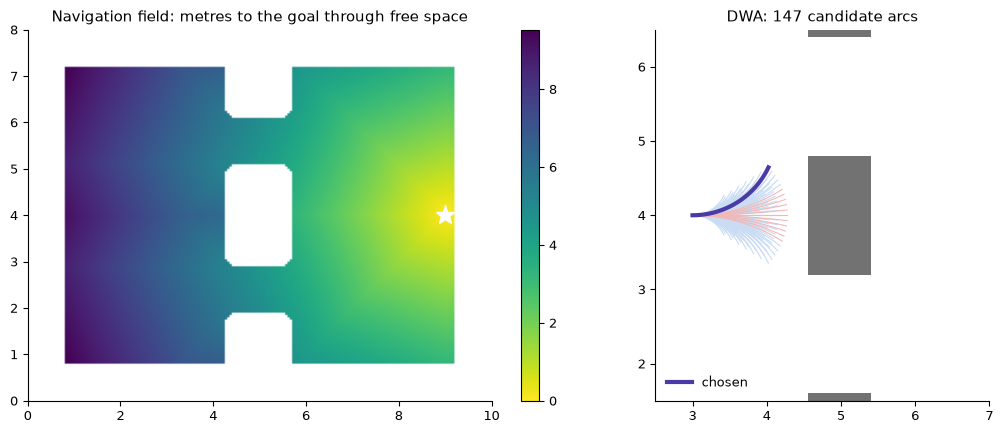

safe candidates: 136 of 147; chosen v = 0.85 m/s, w = +0.75 rad/s


In [25]:
doorway = GRIDS["doorway"]
dwa = DWAController.from_config(cfg, uni, np.array(doorway.goal))
state = uni.reset(pose=(3.0, 4.0, 0.0), v=0.6)
result = dwa.evaluate(state, doorway, dt)

vv, ww = np.meshgrid(result.v_grid, result.w_grid, indexing="ij")
times = np.arange(0.0, dwa.horizon_s + dwa.sample_dt, dwa.sample_dt)
arcs, _ = rollout_arcs(state, vv.ravel(), ww.ravel(), times)
nav = doorway.navigation(np.array(doorway.goal), uni.collision_radius)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x0, y0, x1, y1 = doorway.bounds
im = axes[0].imshow(np.where(np.isfinite(nav), nav, np.nan), origin="lower",
                    extent=(x0, x1, y0, y1), cmap="viridis_r")
axes[0].plot(*doorway.goal, "*", color="white", ms=14)
axes[0].set(title="Navigation field: metres to the goal through free space", aspect="equal")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.035)

draw_room(axes[1], doorway, "DWA: 147 candidate arcs")
for i in range(len(arcs)):
    axes[1].plot(arcs[i, :, 0], arcs[i, :, 1], lw=0.8,
                 color="#c9dcf3" if result.feasible[i] else "#f2b8b7")
best = int(np.argmax(result.scores))
axes[1].plot(arcs[best, :, 0], arcs[best, :, 1], color=VIOLET, lw=3, label="chosen")
axes[1].set(xlim=(2.5, 7), ylim=(1.5, 6.5))
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()
save_fig("08_s5_dwa_arcs")
print(f"safe candidates: {result.feasible.sum()} of {result.feasible.size}; "
      f"chosen v = {result.command[0]:.2f} m/s, w = {result.command[1]:+.2f} rad/s")

### 5.3 The risk signal

Risk answers a different question from confidence:

- **confidence** asks *"is this what the user meant?"*
- **risk** asks *"does it matter if it isn't?"*

A wrong command in the middle of an empty corridor is harmless; the same command half a metre from a door frame is not.

Risk comes from **time to collision**, computed on the **user's** command (not the blended one), because the question is "how bad would it be to obey?". It is then mapped to $[0, 1]$ and smoothed with a 0.3 s lag, so it can't jump around faster than the chair can respond:

$$r_{raw} = \begin{cases} 0 & \text{TTC} \ge 3.0\text{ s} \\ \dfrac{3.0 - \text{TTC}}{3.0 - 0.5} & 0.5 < \text{TTC} < 3.0 \\ 1 & \text{TTC} \le 0.5\text{ s} \end{cases} \qquad r \leftarrow r + \big(1 - e^{-\Delta t / 0.3}\big)\,(r_{raw} - r)$$

The update line is the exact discrete form of a first-order lag. The `no_risk_term` ablation forces $r = 0$.

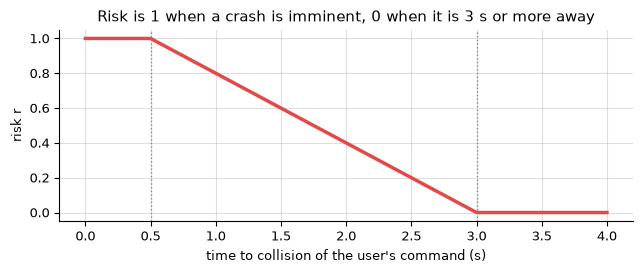

In [26]:
@dataclass
class RiskSignal:
    horizon_s: float = 3.0
    floor_s: float = 0.5
    smoothing_tau: float = 0.30
    sample_dt: float = 0.05
    force_zero: bool = False
    _r: float = 0.0
    _ttc: float = float("inf")

    @classmethod
    def from_config(cls, cfg):
        sec = cfg.section("control.risk")
        return cls(horizon_s=float(sec["horizon_s"]), floor_s=float(sec["floor_s"]),
                   smoothing_tau=float(sec["smoothing_tau"]),
                   force_zero=bool(sec.get("force_zero", False)))

    @property
    def value(self):
        return 0.0 if self.force_zero else self._r

    @property
    def ttc(self):
        return self._ttc

    def reset(self):
        self._r = 0.0
        self._ttc = float("inf")

    def raw_from_ttc(self, ttc):
        if ttc >= self.horizon_s:
            return 0.0
        if ttc <= self.floor_s:
            return 1.0
        span = self.horizon_s - self.floor_s
        return float((self.horizon_s - ttc) / span) if span > 0 else 1.0

    def update(self, grid, state, command, radius, dt):
        if self.force_zero or grid is None:          # ablation
            self._ttc = float(self.horizon_s)
            self._r = 0.0
            return 0.0
        self._ttc = time_to_collision(grid, state, float(command[0]), float(command[1]),
                                      radius, self.horizon_s, self.sample_dt)
        target = self.raw_from_ttc(self._ttc)
        if self.smoothing_tau > 0.0:                 # first-order lag
            lam = 1.0 - float(np.exp(-dt / self.smoothing_tau))
            self._r += lam * (target - self._r)
        else:
            self._r = target
        return self._r


risk_demo = RiskSignal.from_config(cfg)
ttc_axis = np.linspace(0, 4, 200)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(ttc_axis, [risk_demo.raw_from_ttc(x) for x in ttc_axis], color=RED, lw=2.5)
for x in (risk_demo.floor_s, risk_demo.horizon_s):
    ax.axvline(x, color=GREY, ls=":", lw=1)
ax.set(xlabel="time to collision of the user's command (s)", ylabel="risk r",
       title="Risk is 1 when a crash is imminent, 0 when it is 3 s or more away")
fig.tight_layout()
save_fig("09_s5_risk_ramp")

### 5.4 Six ways to share control

All six share one interface (a `combine` method), so they can be swapped by name. Here α is the user's share: α = 1 means the user drives alone, α = 0 means the autopilot does. Each blending rule computes

$$u = \alpha\, u_{user} + (1-\alpha)\, u_{auto}, \qquad u = (v_{cmd}, \omega_{cmd})$$

on the plant's own inputs, then saturates it.

| variant | rule | why it is in the comparison |
|---|---|---|
| `manual_only` | α = 1 | the user alone: baseline |
| `autonomy_only` | α = 0 | the autopilot alone: the other baseline |
| `fixed_blend` | α = 0.5 (and a sweep from 0 to 1) | the simplest sharing rule |
| `confidence_only` | α = confidence | trust the user as much as the decoder trusts itself |
| `adaptive` | α = confidence × (1 − risk), gated and smoothed | **the rule under study** |
| `safety_filter` | pass the user's command through untouched unless TTC < 1.5 s, then use the *closest safe* command | never averages |

**Inside `adaptive`.** The raw target $c\,(1-r)$ keeps the user in control only when the decoder is confident **and** the situation is safe. Three things are added on top:

- **A Schmitt trigger**, a switch with **hysteresis** (different thresholds for switching on and off). When the raw value drops below 0.40 the gate **closes** and α heads to 0; it only **reopens** once the raw value rises above 0.60. In between, it keeps its previous state. Without that dead zone, a value hovering near one threshold would flip control back and forth 50 times a second.
- **Smoothing** (a 0.25 s lag) and a **rate limit** (|dα/dt| ≤ 2 per second). α multiplies a feedback path, so it has to change slowly compared with the chair itself.

**The safety filter** passes the user's command through untouched while TTC > 1.5 s. Below that, it searches DWA's 147 candidates for the safe one **closest to what the user asked for**. Distance is measured after dividing by each limit, $(\Delta v / v_{max})^2 + (\Delta\omega/\omega_{max})^2$, because m/s and rad/s can't be compared directly. It reports an *effective* α: where its output sits on the line between the user's command and the autopilot's.

In [27]:
@dataclass
class ArbitrationContext:
    state: np.ndarray
    u_bci: np.ndarray          # user's command
    u_auto: np.ndarray         # autopilot's command
    confidence: float = 1.0
    risk: float = 0.0
    ttc: float = float("inf")
    dt: float = 0.02
    plant: object = None
    grid: object = None
    dwa: object = None
    dwa_result: object = None


def effective_alpha(u, u_bci, u_auto):
    # where u sits between auto (0) and user (1)
    diff = np.asarray(u_bci, float) - np.asarray(u_auto, float)
    denom = float(diff @ diff)
    if denom < 1e-12:
        return 1.0
    a = float((np.asarray(u, float) - np.asarray(u_auto, float)) @ diff / denom)
    return float(np.clip(a, 0.0, 1.0))


class Arbitrator(ABC):
    name = "base"

    def reset(self):
        pass

    @abstractmethod
    def alpha(self, ctx):
        ...

    def combine(self, ctx):
        a = float(np.clip(self.alpha(ctx), 0.0, 1.0))
        u = a * np.asarray(ctx.u_bci, float) + (1.0 - a) * np.asarray(ctx.u_auto, float)
        if ctx.plant is not None:
            u = ctx.plant.saturate(u)
        return u, a


class ManualOnly(Arbitrator):
    name = "manual_only"

    def alpha(self, ctx):
        return 1.0


class AutonomyOnly(Arbitrator):
    name = "autonomy_only"

    def alpha(self, ctx):
        return 0.0


@dataclass
class FixedBlend(Arbitrator):
    alpha_const: float = 0.5
    name: str = "fixed_blend"

    def alpha(self, ctx):
        return float(self.alpha_const)


@dataclass
class ConfidenceOnly(Arbitrator):
    name: str = "confidence_only"

    def alpha(self, ctx):
        return float(np.clip(ctx.confidence, 0.0, 1.0))


@dataclass
class Adaptive(Arbitrator):
    alpha_min: float = 0.0
    alpha_max: float = 1.0
    hysteresis_high: float = 0.60
    hysteresis_low: float = 0.40
    rate_limit_per_s: float = 2.0
    smoothing_tau: float = 0.25
    name: str = "adaptive"
    _open: bool = field(default=True, repr=False)
    _alpha: float = field(default=1.0, repr=False)

    def reset(self):
        self._open = True
        self._alpha = float(self.alpha_max)

    def alpha(self, ctx):
        raw = float(np.clip(ctx.confidence, 0.0, 1.0)) * (1.0 - float(np.clip(ctx.risk, 0.0, 1.0)))
        if self._open and raw < self.hysteresis_low:         # Schmitt trigger
            self._open = False
        elif not self._open and raw > self.hysteresis_high:
            self._open = True
        target = (float(np.clip(raw, self.alpha_min, self.alpha_max)) if self._open
                  else float(self.alpha_min))
        step_dt = max(float(ctx.dt), 1e-9)
        if self.smoothing_tau > 0.0:                         # first-order lag
            lam = 1.0 - float(np.exp(-step_dt / self.smoothing_tau))
            proposed = self._alpha + lam * (target - self._alpha)
        else:
            proposed = target
        max_step = self.rate_limit_per_s * step_dt           # rate limit
        self._alpha += float(np.clip(proposed - self._alpha, -max_step, max_step))
        return float(np.clip(self._alpha, 0.0, 1.0))


@dataclass
class SafetyFilter(Arbitrator):
    ttc_threshold_s: float = 1.5
    max_deviation: float = None
    name: str = "safety_filter"

    def alpha(self, ctx):
        return self.combine(ctx)[1]

    def combine(self, ctx):
        u_bci = np.asarray(ctx.u_bci, dtype=float)
        if ctx.ttc > self.ttc_threshold_s or ctx.grid is None or ctx.dwa is None:
            u = ctx.plant.saturate(u_bci) if ctx.plant is not None else u_bci
            return u, effective_alpha(u, ctx.u_bci, ctx.u_auto)      # pass through
        result = ctx.dwa_result if ctx.dwa_result is not None else ctx.dwa.evaluate(ctx.state, ctx.grid, ctx.dt)
        vv, ww = np.meshgrid(result.v_grid, result.w_grid, indexing="ij")
        v_flat, w_flat = vv.ravel(), ww.ravel()
        if not result.feasible.any():                                # nothing safe
            u = ctx.plant.saturate(result.command)
            return u, effective_alpha(u, ctx.u_bci, ctx.u_auto)
        p = ctx.plant
        dv = (v_flat - u_bci[0]) / max(p.v_max, 1e-9)                # unit-free
        dw = (w_flat - u_bci[1]) / max(p.w_max, 1e-9)
        dist = np.where(result.feasible, dv * dv + dw * dw, np.inf)
        if self.max_deviation is not None:
            allowed = dist <= self.max_deviation**2
            if allowed.any():
                dist = np.where(allowed, dist, np.inf)
        best = int(np.argmin(dist))                                  # closest safe
        u = np.array([v_flat[best], w_flat[best]])
        if ctx.plant is not None:
            u = ctx.plant.saturate(u)
        return u, effective_alpha(u, ctx.u_bci, ctx.u_auto)


def make_arbitrator(name, cfg, *, alpha_const=None):
    if name == "manual_only":
        return ManualOnly()
    if name == "autonomy_only":
        return AutonomyOnly()
    if name == "fixed_blend":
        default = float(cfg["control.arbitration.fixed_blend.alpha_default"])
        return FixedBlend(alpha_const=default if alpha_const is None else alpha_const)
    if name == "confidence_only":
        return ConfidenceOnly()
    if name == "adaptive":
        sec = cfg.section("control.arbitration.adaptive")
        return Adaptive(alpha_min=float(sec["alpha_min"]), alpha_max=float(sec["alpha_max"]),
                        hysteresis_high=float(sec["hysteresis_high"]),
                        hysteresis_low=float(sec["hysteresis_low"]),
                        rate_limit_per_s=float(sec["rate_limit_per_s"]),
                        smoothing_tau=float(sec["smoothing_tau"]))
    if name == "safety_filter":
        sec = cfg.section("control.arbitration.safety_filter")
        return SafetyFilter(ttc_threshold_s=float(sec["ttc_threshold_s"]),
                            max_deviation=sec.get("max_deviation"))
    raise ValueError(f"unknown arbitration variant {name!r}; expected one of {VARIANTS}")


[make_arbitrator(v, cfg).name for v in VARIANTS]

['manual_only',
 'autonomy_only',
 'fixed_blend',
 'confidence_only',
 'adaptive',
 'safety_filter']

**Watching the adaptive gate.** The next cell feeds a made-up confidence and risk sequence into the real `Adaptive` class, so you can see each piece act.

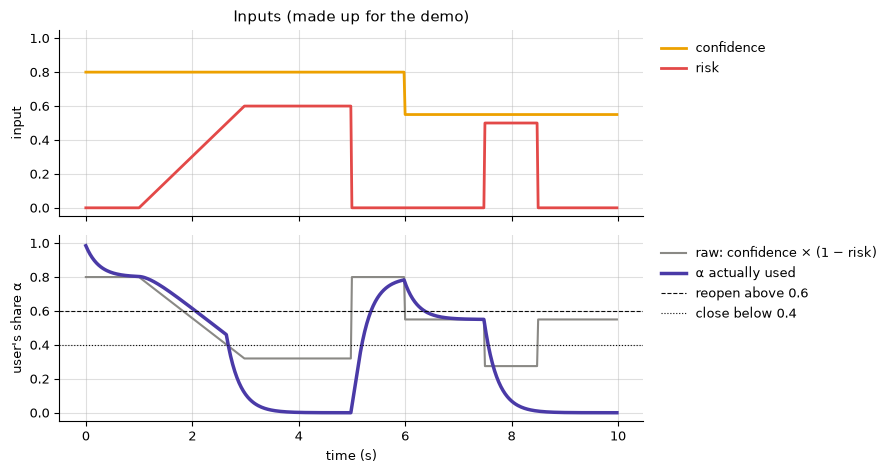

In [28]:
t = np.arange(0, 10, dt)
conf_seq = np.where(t < 6, 0.8, 0.55)
risk_seq = np.zeros_like(t)
ramp = (t >= 1) & (t < 3)
risk_seq[ramp] = np.linspace(0, 0.6, ramp.sum())
risk_seq[(t >= 3) & (t < 5)] = 0.6
risk_seq[(t >= 7.5) & (t < 8.5)] = 0.5

adaptive = make_arbitrator("adaptive", cfg)
adaptive.reset()
raw, alpha = [], []
for c, r in zip(conf_seq, risk_seq):
    raw.append(c * (1 - r))
    alpha.append(adaptive.alpha(ArbitrationContext(state=None, u_bci=np.zeros(2), u_auto=np.zeros(2),
                                                   confidence=c, risk=r, dt=dt)))

hi = cfg["control.arbitration.adaptive.hysteresis_high"]
lo = cfg["control.arbitration.adaptive.hysteresis_low"]
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True)
axes[0].plot(t, conf_seq, color=YELLOW, lw=2, label="confidence")
axes[0].plot(t, risk_seq, color=RED, lw=2, label="risk")
axes[0].set(ylabel="input", ylim=(-0.05, 1.05), title="Inputs (made up for the demo)")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].plot(t, raw, color=GREY, lw=1.5, label="raw: confidence × (1 − risk)")
axes[1].plot(t, alpha, color=VIOLET, lw=2.5, label="α actually used")
axes[1].axhline(hi, color=INK, ls="--", lw=0.8, label=f"reopen above {hi}")
axes[1].axhline(lo, color=INK, ls=":", lw=0.8, label=f"close below {lo}")
axes[1].set(xlabel="time (s)", ylabel="user's share α", ylim=(-0.05, 1.05))
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
save_fig("10_s5_adaptive_gate")

**Reading it, left to right:**

- **0–2 s:** safe and confident, so α settles to the raw value, 0.8.
- **~2.5 s:** risk rises, the raw value falls below 0.40, and the gate **closes**: α slides smoothly to 0.
- **5 s:** risk clears, the raw value jumps to 0.8 (above 0.60), and the gate **reopens**.
- **6 s:** confidence drops to 0.55. That's between the thresholds, so the gate **stays open**.
- **7.5–8.5 s:** a short risk spike closes the gate.
- **After 8.5 s:** the raw value is back at 0.55, still *below* 0.60, so the gate **stays closed**. That's hysteresis: the same input (0.55) gives a different output depending on history.

### 5.5 The averaging trap

This is the reason the comparison includes a rule that never averages. Put the chair in the doorway, heading at the pillar at 0.6 m/s. The **user** turns left around it ($\omega$ = +0.6); the **autopilot** turns right around it ($\omega$ = −0.6). Both are safe. The 50/50 blend has $\omega = 0$, **no turn at all**, while the forward speed is unchanged, so it drives straight into the pillar both of them were avoiding.

The safety filter, given the same two commands, never averages them.

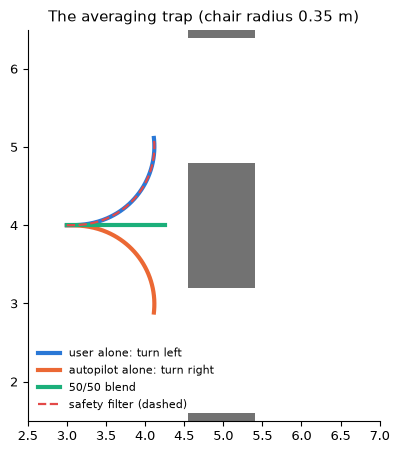

,collided,closest approach (m)
policy,,
user alone: turn left,False,0.453
autopilot alone: turn right,False,0.453
50/50 blend,True,0.300
safety filter (dashed),False,0.453


In [29]:
left, right = np.array([0.6, 0.6]), np.array([0.6, -0.6])   # [v, w]
blend = FixedBlend(alpha_const=0.5)
safety = make_arbitrator("safety_filter", cfg)
horizon = cfg["control.risk.horizon_s"]


def drive(command_fn, seconds=3.0, pose=(3.0, 4.0, 0.0)):
    state = uni.reset(pose=pose, v=0.6)
    path, closest = [state[:2].copy()], np.inf
    for _ in range(int(seconds / dt)):
        state = uni.step(state, command_fn(state), dt)
        path.append(state[:2].copy())
        clearance = float(doorway.clearance(state[:2]))
        closest = min(closest, clearance)
        if clearance <= uni.collision_radius:
            return np.array(path), True, closest
    return np.array(path), False, closest


def blended(s):
    return blend.combine(ArbitrationContext(state=s, u_bci=left, u_auto=right, plant=uni))[0]


def filtered(s):
    ttc_now = time_to_collision(doorway, s, left[0], left[1], uni.collision_radius, horizon, 0.05)
    return safety.combine(ArbitrationContext(state=s, u_bci=left, u_auto=right, ttc=ttc_now,
                                             dt=dt, plant=uni, grid=doorway, dwa=dwa))[0]


cases = {"user alone: turn left": (lambda s: left, BLUE),
         "autopilot alone: turn right": (lambda s: right, ORANGE),
         "50/50 blend": (blended, GREEN),
         "safety filter (dashed)": (filtered, RED)}
fig, ax = plt.subplots(figsize=(6, 4.6))
draw_room(ax, doorway, "The averaging trap (chair radius 0.35 m)")
rows = []
for name, (fn, color) in cases.items():
    path, hit, closest = drive(fn)
    dashed = name.startswith("safety")
    ax.plot(path[:, 0], path[:, 1], color=color, lw=1.6 if dashed else 3, ls="--" if dashed else "-", label=name)
    rows.append({"policy": name, "collided": hit, "closest approach (m)": round(closest, 3)})
ax.set(xlim=(2.5, 7), ylim=(1.5, 6.5))
ax.legend(frameon=False, loc="lower left", fontsize=8)
fig.tight_layout()
save_fig("11_s5_averaging_trap")
pd.DataFrame(rows).set_index("policy")

**Reading it.** Each command on its own keeps 0.45 m from the obstacles. The blend gets to 0.30 m, inside the chair's 0.35 m radius: a crash. The safety filter keeps the user's already-safe left turn instead of averaging it away. Blending acts on $(v_{cmd}, \omega_{cmd})$, the plant's own inputs, *on purpose*, so that this failure shows up instead of being hidden.

---
## 6. The simulation study

### 6.1 One drive, step by step

An **episode** is one drive from start to goal in one room, for one subject, with one sharing rule. Every 20 ms step, in this order:

1. The **user** looks at the chair as it was 0.2 s ago and forms an intent (Section 4).
2. The **channel** samples, delays and maybe corrupts that intent, and attaches a confidence (Section 2).
3. The intent becomes $u_{user} = (v_{cmd}, \omega_{cmd})$ using the **user's delayed view of the position** and the chair's current heading.
4. The **autopilot** plans from the **true current** state every 0.1 s (and outputs zero once it's within 0.35 m of the goal), holding its command in between.
5. **Risk** is evaluated on the user's command every 0.1 s, the same rate as planning. Computing a TTC every 20 ms used to dominate the run time, and a wheelchair's situation doesn't change meaningfully at 50 Hz.
6. The **sharing rule** makes the final command, and the chair moves one step.

The drive ends when the chair gets within 0.35 m of the goal (**success**), **hits something** (a crash ends the drive, because a wheelchair that hits a door frame has failed; letting it carry on would score an impossible drive as a success), or reaches **60 s** (timeout).

**Logged metrics.** success, collisions, time to goal, path length ÷ straight-line distance, number of decoder decisions, **intervention fraction** (share of steps where the motors got something different from the user's command), mean α, minimum TTC, cross-track RMS (how far the path strays sideways from the start–goal line), terminal error, and the share of steps spent on a wrong command.

**Pairing.** The random-number generator for a drive is seeded from (subject, room, seed, burst setting) and deliberately **not** from the sharing rule. `zlib.crc32` turns that key into a stable number. (Python's built-in `hash()` would change between runs.) So all six rules meet *exactly* the same decoder mistakes, latencies and confidences, and any difference between them is caused by the rule alone.

In [30]:
def episode_rng(seed, *keys):
    tag = "|".join(str(k) for k in keys).encode("utf-8")
    return np.random.default_rng([seed, zlib.crc32(tag)])


METRICS = ["success", "collisions", "time_to_goal", "path_length_ratio", "commands_issued",
           "intervention_fraction", "mean_alpha", "min_time_to_collision",
           "cross_track_rms", "terminal_error", "degraded_fraction"]


@dataclass
class EpisodeResult:
    success: bool
    collisions: int
    time_to_goal: float
    path_length_ratio: float
    commands_issued: int
    intervention_fraction: float
    mean_alpha: float
    min_time_to_collision: float
    cross_track_rms: float
    terminal_error: float
    degraded_fraction: float
    trace: dict = field(default=None, repr=False)

    def as_row(self):
        return {k: getattr(self, k) for k in METRICS}


def cross_track_rms(points, start, goal):
    d = goal - start
    length = float(np.hypot(d[0], d[1]))
    if length < 1e-9:
        return 0.0
    n = np.array([-d[1], d[0]]) / length          # unit normal to start-goal line
    return float(np.sqrt(np.mean(((points - start) @ n) ** 2)))


def run_episode(cfg, plant, grid, arbitrator, channel, rng, *, record=False):
    dt = float(cfg["plants.dt"])
    t_max = float(cfg["experiment.episode_timeout_s"])
    n_steps = int(round(t_max / dt))
    goal = np.array(grid.goal, dtype=float)
    start = np.array(grid.start[:2], dtype=float)
    tolerance = float(cfg["control.dwa.goal_tolerance"])
    iid = bool(cfg["command_error.iid_override"])

    operator = DelayedPDOperator.from_config(cfg, goal)
    dwa = DWAController.from_config(cfg, plant, goal)
    risk = RiskSignal.from_config(cfg)

    state = plant.reset(pose=grid.start)
    operator.reset(dt, state[:2], plant.world_velocity(state))
    channel.reset(rng)
    arbitrator.reset()
    risk.reset()

    plan_every = max(1, int(round(dwa.plan_period_s / dt)))
    u_auto = np.zeros(2)
    dwa_result = None
    positions = [state[:2].copy()]
    alphas, degraded_flags, ttcs = [], [], []
    interventions = collisions = 0
    in_collision = reached = False
    path_length = 0.0
    time_to_goal = t_max
    trace = {"t": [], "pos": [], "alpha": [], "ttc": [], "conf": [],
             "risk": [], "degraded": []} if record else None

    for k in range(n_steps):
        t = k * dt
        intent = operator.intent(state[:2], plant.world_velocity(state))       # 1. user
        out = channel.step(intent, float(state[2]), dt, rng, iid=iid)         # 2. channel
        perceived = operator.perceived_state()
        seen = np.array([perceived[0], perceived[1], state[2], state[3], state[4]])
        u_bci = plant.command_from_intent(seen, out.intent)                   # 3. user command

        if k % plan_every == 0:                                               # 4. autopilot
            dwa_result = dwa.evaluate(state, grid, dt)
            near_goal = float(np.hypot(*(state[:2] - goal))) <= tolerance
            u_auto = np.zeros(2) if near_goal else dwa_result.command
        if k % plan_every == 0:                                               # 5. risk
            r = risk.update(grid, state, u_bci, plant.collision_radius, dwa.plan_period_s)
        else:
            r = risk.value

        u, alpha = arbitrator.combine(ArbitrationContext(                     # 6. share
            state=state, u_bci=u_bci, u_auto=u_auto, confidence=out.confidence,
            risk=r, ttc=risk.ttc, dt=dt, plant=plant, grid=grid, dwa=dwa,
            dwa_result=dwa_result))

        if float(np.hypot(*(u - u_bci))) > 1e-3:
            interventions += 1
        alphas.append(alpha)
        degraded_flags.append(out.degraded)
        ttcs.append(risk.ttc)
        if record:
            for key, value in (("t", t), ("pos", state[:2].copy()), ("alpha", alpha),
                               ("ttc", risk.ttc), ("conf", out.confidence),
                               ("risk", r), ("degraded", out.degraded)):
                trace[key].append(value)

        prev = state[:2].copy()
        state = plant.step(state, u, dt)
        path_length += float(np.hypot(*(state[:2] - prev)))
        positions.append(state[:2].copy())

        if plant.is_collision(state, grid):                                   # crash ends it
            collisions, in_collision, time_to_goal = 1, True, t + dt
            break
        if float(np.hypot(*(state[:2] - goal))) <= tolerance:
            reached, time_to_goal = True, t + dt
            break

    pts = np.asarray(positions)
    straight = float(np.hypot(*(goal - start)))
    n_used = max(len(alphas), 1)
    return EpisodeResult(
        success=bool(reached and not in_collision), collisions=collisions,
        time_to_goal=time_to_goal,
        path_length_ratio=(path_length / straight) if straight > 1e-9 else float("nan"),
        commands_issued=channel._n,
        intervention_fraction=interventions / n_used,
        mean_alpha=float(np.mean(alphas)) if alphas else float("nan"),
        min_time_to_collision=float(np.min(ttcs)) if ttcs else float("nan"),
        cross_track_rms=cross_track_rms(pts, start, goal),
        terminal_error=float(np.hypot(*(pts[-1] - goal))),
        degraded_fraction=float(np.mean(degraded_flags)) if degraded_flags else 0.0,
        trace={k: np.asarray(v) for k, v in trace.items()} if record else None)

### 6.2 The experiment grid

The main comparison is 6 rules × 9 subjects × 3 rooms × 20 seeds = **3,240 drives**. On top of that come:

- an **α sweep** of the fixed blend from 0 to 1 in steps of 0.1;
- a **burstiness sweep**: errors made ×1, ×1.5, ×2.5 and ×4 as streaky as coin flips, holding each subject's error rate fixed (Section 2.2);
- six **ablations**. An *ablation* switches one thing off and re-runs everything with the same seeds, to measure how much that piece mattered.

That makes **32,400 drives** in total. `run_one` below reproduces the original simulator's experiment runner exactly. Each ablation is a config made with `with_overrides`, and `fixed_alpha` pins the rule to the fixed blend.

In [31]:
ABLATION_CFGS = {name: cfg.with_overrides(over) for name, over in cfg["experiment.ablations"].items()}


def run_one(variant, subject, room, seed, *, cfg_=cfg, alpha_const=None, burst=None, record=False):
    m = MODELS[subject]
    markov = m["markov"]
    if burst is not None:        # multiplier of this subject's coin-flip burst
        markov = markov.with_burst_length(float(burst) * markov.iid_mean_burst_length)
    channel = CommandChannel.from_config(cfg_, markov, m["latency"], m["confusion"], m["confidences"])
    arbitrator = make_arbitrator(variant, cfg_, alpha_const=alpha_const)
    rng = episode_rng(int(cfg_["meta.seed"]), subject, room, seed, burst)   # no variant in the key
    return run_episode(cfg_, Unicycle.from_config(cfg_), GRIDS[room], arbitrator, channel, rng,
                       record=record)


def condition_settings(row):
    # saved log row -> how to re-run it
    cfg_ = ABLATION_CFGS[row.condition.split(":", 1)[1]] if row.condition.startswith("ablation:") else cfg
    alpha = None if pd.isna(row.alpha_const) else float(row.alpha_const)
    burst = None if pd.isna(row.burst_multiplier) else float(row.burst_multiplier)
    return cfg_, alpha, burst


log = pd.read_csv(EPISODES_CSV, float_precision="round_trip")
print(f"saved log: {len(log)} drives")
log.condition.value_counts()

saved log: 32400 drives


condition
burstiness                     6480
alpha_sweep                    5940
main                           3240
ablation:no_delay              3240
ablation:no_burst_errors       3240
ablation:perfect_confidence    3240
ablation:no_risk_term          3240
ablation:confidence_decay      3240
ablation:fixed_alpha            540
Name: count, dtype: int64

### 6.3 Watching one drive: subject 3, doorway, seed 0

Same subject, same room, same decoder mistakes, six different sharing rules.

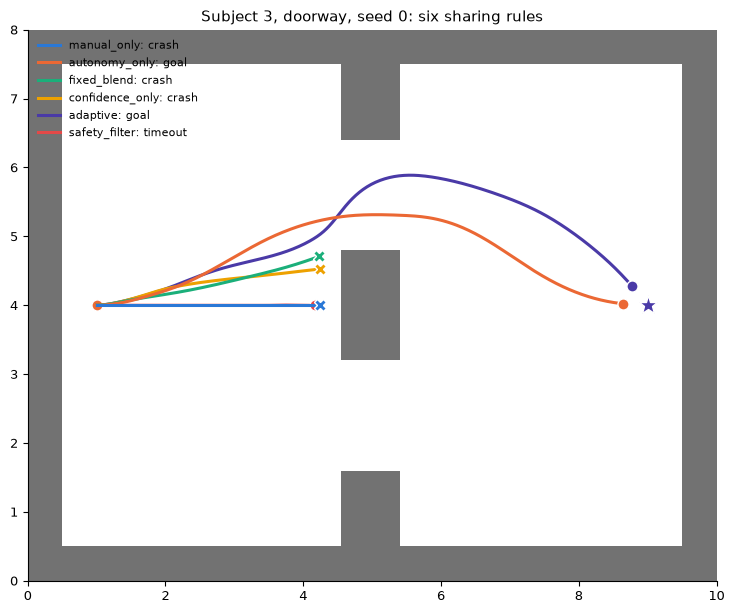

,success,saved log,time (s),saved time,mean α,steps on a wrong command
manual_only,False,False,5.36,5.36,1.000,0%
autonomy_only,True,True,8.40,8.40,0.000,0%
fixed_blend,False,False,5.04,5.04,0.500,0%
confidence_only,False,False,4.44,4.44,0.522,0%
adaptive,True,True,9.42,9.42,0.196,0%
safety_filter,False,False,60.00,60.00,0.553,24%


In [32]:
traced = {v: run_one(v, 3, "doorway", 0, record=True) for v in VARIANTS}
saved_main = log[log.condition == "main"]
saved = saved_main[(saved_main.subject == 3) & (saved_main.environment == "doorway")
                   & (saved_main.seed == 0)].set_index("variant")

fig, ax = plt.subplots(figsize=(8, 6.2))
draw_room(ax, doorway, "Subject 3, doorway, seed 0: six sharing rules")
for v, res in reversed(traced.items()):      # user-alone on top
    p = res.trace["pos"]
    outcome = "goal" if res.success else ("crash" if res.collisions else "timeout")
    ax.plot(p[:, 0], p[:, 1], color=COLORS[v], lw=2.2, label=f"{v}: {outcome}")
    ax.plot(*p[-1], "X" if res.collisions else "o", color=COLORS[v], ms=8, mec="white")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()
save_fig("12_s6_six_paths_doorway")

pd.DataFrame({
    "success": {v: r.success for v, r in traced.items()},
    "saved log": saved.success.astype(bool),
    "time (s)": {v: round(r.time_to_goal, 2) for v, r in traced.items()},
    "saved time": saved.time_to_goal.round(2),
    "mean α": {v: round(r.mean_alpha, 3) for v, r in traced.items()},
    "steps on a wrong command": {v: f"{r.degraded_fraction:.0%}" for v, r in traced.items()},
}).loc[list(VARIANTS)]

**Reading it.** The user alone, the fixed blend and confidence-only all crash into the pillar within about 5 s. The autopilot and adaptive both pick a gap and reach the goal. The safety filter never crashes but stalls in front of the pillar until the 60 s clock runs out. The numbers simulated by this notebook match the saved log.

Look at the last column: **the decoder made no mistakes during the first 10 seconds of this drive.** Only the 60-second safety-filter drive lasted long enough to meet some. The three crashes happened anyway, because the model user aims straight at the goal, through the pillar (Section 4).

### 6.4 Does this notebook's code reproduce the saved log?

Copying 1,000 lines of code into a notebook is exactly the kind of step where a small slip changes the results without anyone noticing. So this cell picks 8 random drives from **every condition** in the saved log (main, α sweep, burstiness, all six ablations), re-simulates them with the code above, and compares **all 11 logged metrics**.

In [33]:
started = time.time()
EXACT = ["success", "collisions", "time_to_goal", "commands_issued"]   # discrete outcomes
sample = log.groupby("condition", group_keys=False).sample(n=8, random_state=0)
rows = []
for row in sample.itertuples(index=False):
    cfg_, alpha, burst = condition_settings(row)
    res = run_one(row.variant, int(row.subject), row.environment, int(row.seed),
                  cfg_=cfg_, alpha_const=alpha, burst=burst)
    new = {k: float(v) for k, v in res.as_row().items()}
    old = {k: float(getattr(row, k)) for k in METRICS}
    rows.append({
        "condition": row.condition,
        "outcome identical": all(new[k] == old[k] for k in EXACT),
        "all 11 bit-identical": all(new[k] == old[k] for k in METRICS),
        "largest relative difference": max(abs(new[k] - old[k]) / max(abs(old[k]), 1e-12) for k in METRICS),
    })
check = pd.DataFrame(rows)
print(f"{len(check)} drives re-simulated in {time.time() - started:.0f} s")
print(f"same outcome, time and number of decisions: {check['outcome identical'].sum()} of {len(check)}")
print(f"all 11 metrics bit-for-bit identical: {check['all 11 bit-identical'].sum()} of {len(check)}")
print(f"largest relative difference in any metric: {check['largest relative difference'].max():.1e}")
check_summary = check.groupby("condition").agg({"outcome identical": "mean", "all 11 bit-identical": "mean",
                                                "largest relative difference": "max"})
check_summary.to_csv(TABLES / "reproduction_check.csv")
check_summary

72 drives re-simulated in 19 s
same outcome, time and number of decisions: 72 of 72
all 11 metrics bit-for-bit identical: 49 of 72
largest relative difference in any metric: 1.1e-09


,outcome identical,all 11 bit-identical,largest relative difference
condition,,,
ablation:confidence_decay,1.0,0.875,3.694531e-16
ablation:fixed_alpha,1.0,1.000,0.000000e+00
ablation:no_burst_errors,1.0,0.375,6.967134e-11
ablation:no_delay,1.0,0.500,1.094296e-09
ablation:no_risk_term,1.0,0.625,7.544056e-15
ablation:perfect_confidence,1.0,0.750,1.269650e-16
alpha_sweep,1.0,0.875,1.599938e-16
burstiness,1.0,0.625,1.494001e-10
main,1.0,0.500,7.544029e-15


Every re-simulated drive, in every condition, has the same outcome, the same end time and the same number of decoder decisions as the saved log, and all 11 metrics agree to within about one part in a billion. So the code in this notebook reproduces the experiment that made `results/part2/episodes.csv`, and the rest of this section can analyse the saved 32,400-drive log instead of re-running 39 minutes of simulation.

Why aren't they all *bit*-identical? Two harmless reasons. The saved log was made on a different PC, and on a different CPU or NumPy build a sum or square root can round differently in the 16th significant digit. And the decoder confidences that Part 1 regenerates on your machine can differ from the original run in about the 9th decimal place. Both show up only as tiny differences in continuous metrics such as mean α or path length, never in an outcome.

If `RUN_FULL_MAIN_GRID` is `True`, the next cell re-runs all 3,240 main drives here and uses them instead of the saved log. (That was done once while this notebook was being built: all 3,240 drives gave the same outcome, time and decision count as the saved log, and every metric agreed to within 5 × 10⁻¹⁴.)

In [34]:
if RUN_FULL_MAIN_GRID:
    started = time.time()
    rows = []
    for v in VARIANTS:
        for s in MODELS:
            for room in ROOMS:
                for seed in range(cfg["experiment.n_seeds"]):
                    res = run_one(v, s, room, seed)
                    rows.append({"condition": "main", "variant": v, "subject": s,
                                 "environment": room, "seed": seed,
                                 **{k: float(x) for k, x in res.as_row().items()}})
        print(f"  {v:16s} done, {time.time() - started:.0f} s")
    main = pd.DataFrame(rows)
    keys = ["variant", "subject", "environment", "seed"]
    same = main.merge(saved_main, on=keys, suffixes=("", "_saved"))
    print(f"re-ran {len(main)} drives; success identical to the saved log in "
          f"{(same.success == same.success_saved).mean():.1%}")
else:
    main = saved_main.copy()
    print(f"using the saved log: {len(main)} main drives")

using the saved log: 3240 main drives


### 6.5 How much of the user-alone failure is the decoder?

To separate the two causes from 6.3, give the user-alone chair a **perfect decoder** (never wrong, same latencies) and compare it with the real one: 9 subjects × 5 seeds per room.

In [35]:
never_wrong = MarkovErrorModel(subject=0, p_rd=0.0, p_dd=0.0, p_rd_smoothed=0.0,
                               p_dd_smoothed=0.0, marginal_error_rate=0.0)
rows = {}
for room in ROOMS:
    wins = []
    for s, m in MODELS.items():
        for seed in range(5):
            ch = CommandChannel.from_config(cfg, never_wrong, m["latency"], m["confusion"], m["confidences"])
            res = run_episode(cfg, uni, GRIDS[room], make_arbitrator("manual_only", cfg), ch,
                              episode_rng(SEED, s, room, seed, None))
            wins.append(res.success)
    real = main[(main.variant == "manual_only") & (main.environment == room)].success.mean()
    rows[room] = {"perfect decoder": np.mean(wins), "real decoder": real}
pd.DataFrame(rows).round(3)

,corridor,doorway,cluttered
perfect decoder,1.000,0.000,0.0
real decoder,0.333,0.022,0.0


**Reading it.** With a perfect decoder, the user-alone chair always succeeds in the corridor but **still always crashes** in the doorway and the cluttered room. So:

- the **corridor** (100% → 33%) is the clean measure of what the decoder's errors cost;
- in the **other two rooms**, the user-alone failure comes mainly from the obstacle-blind user model, not the decoder. (In the doorway, the real decoder even does slightly *better* than a perfect one, 2% against 0%: now and then a lucky wrong turn sends the chair through a gap.)

The report (`report/report.pdf`) says the same in its limitations section. Remember it whenever you quote "the user alone succeeds 12% of the time": that number measures an obstacle-blind driver as well as a noisy channel.

### 6.6 Inside the adaptive drive

What did adaptive actually do in the drive from 6.3? Grey shading would mark any time the command in use came from a **wrong** decoder decision (there were none in this drive, as the table showed).

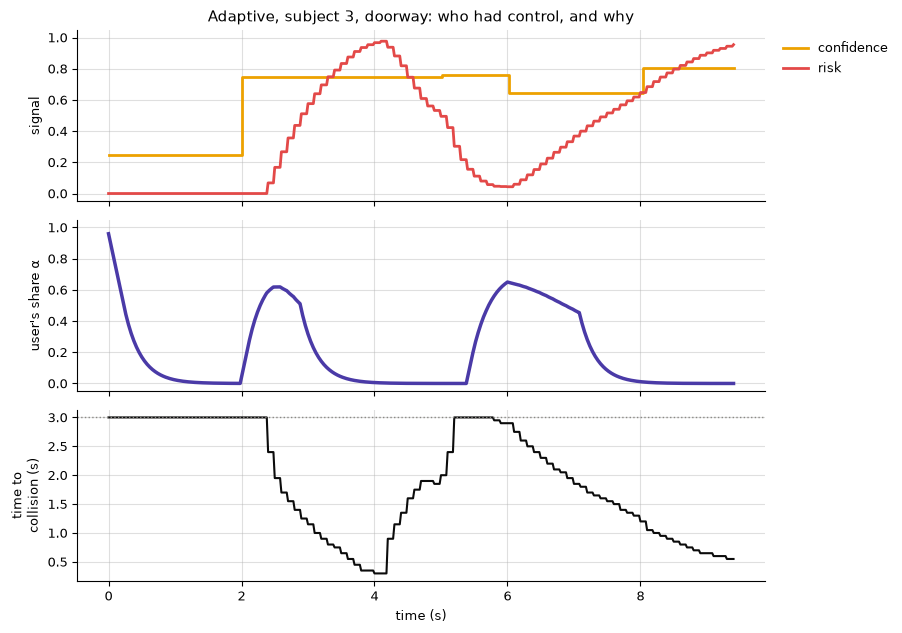

In [36]:
tr_ad = traced["adaptive"].trace
t = tr_ad["t"]
fig, axes = plt.subplots(3, 1, figsize=(9, 6.4), sharex=True)
for ax in axes:
    ax.fill_between(t, 0, 1, where=tr_ad["degraded"], color=GREY, alpha=0.25,
                    transform=ax.get_xaxis_transform(), lw=0)
axes[0].step(t, tr_ad["conf"], where="post", color=YELLOW, lw=2, label="confidence")
axes[0].plot(t, tr_ad["risk"], color=RED, lw=2, label="risk")
axes[0].set(ylabel="signal", ylim=(-0.05, 1.05),
            title="Adaptive, subject 3, doorway: who had control, and why")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].plot(t, tr_ad["alpha"], color=VIOLET, lw=2.5)
axes[1].set(ylabel="user's share α", ylim=(-0.05, 1.05))
axes[2].plot(t, tr_ad["ttc"], color=INK, lw=1.5)
axes[2].axhline(cfg["control.risk.horizon_s"], color=GREY, ls=":", lw=1)
axes[2].set(ylabel="time to\ncollision (s)", xlabel="time (s)")
fig.tight_layout()
save_fig("13_s6_adaptive_trace")

**Reading it.**

- **0–2 s:** nothing has arrived from the decoder, confidence sits at the 0.25 prior, the gate closes and the autopilot drives.
- **~2 s:** the first decision arrives with confidence ~0.75 and the path ahead is clear, so the gate reopens and α climbs toward 0.6.
- **~2.5–4 s:** the user's (correct!) command points at the pillar, time to collision falls, risk rises and α drops back to 0. The autopilot steers into a gap.
- **~5.5–7 s:** clear again, so the user gets authority back until the next approach to an obstacle.

The user gets real authority only when the decoder is confident **and** the path ahead is clear. Here risk is protecting against a *correctly decoded but unsafe* command, which confidence could never catch.

### 6.7 The headline: 540 drives per rule

Columns: **success**; **collisions** (share of drives that crashed); **time** (seconds until the drive ended); **mean α** (average user share); **intervention** (share of steps where the motors got something other than the user's command).

In [37]:
headline = main.groupby("variant").agg(
    success=("success", "mean"), collisions=("collisions", "mean"),
    time_s=("time_to_goal", "mean"), mean_alpha=("mean_alpha", "mean"),
    intervention=("intervention_fraction", "mean")).loc[list(VARIANTS)]
by_room = main.pivot_table(index="variant", columns="environment", values="success").loc[list(VARIANTS), ROOMS]
headline.round(4).to_csv(TABLES / "headline_main.csv")
by_room.round(4).to_csv(TABLES / "success_by_room.csv")
display(headline.round(3))
by_room.round(3)

,success,collisions,time_s,mean_alpha,intervention
variant,,,,,
manual_only,0.119,0.881,9.338,1.000,0.000
autonomy_only,1.000,0.000,10.467,0.000,0.913
fixed_blend,0.161,0.839,9.779,0.500,0.933
confidence_only,0.315,0.683,10.165,0.387,0.931
adaptive,0.996,0.004,11.732,0.118,0.914
safety_filter,0.356,0.120,44.816,0.771,0.350


environment,corridor,doorway,cluttered
variant,,,
manual_only,0.333,0.022,0.000
autonomy_only,1.000,1.000,1.000
fixed_blend,0.400,0.083,0.000
confidence_only,0.644,0.267,0.033
adaptive,1.000,1.000,0.989
safety_filter,0.689,0.356,0.022


**Reading it.**

- **The user alone** reaches the goal 12% of the time and crashes in 88% of drives. In the corridor that is mostly the decoder (33% against 100% with a perfect decoder); in the other rooms it is mostly the obstacle-blind user.
- **The fixed 50/50 blend** is barely better (16%); the averaging trap and the bad commands both hurt it.
- **Confidence-only** helps a little (32%). Trusting the decoder's own confidence isn't enough.
- **The safety filter** cuts crashes from 84% (fixed blend) to 12% while keeping the most user authority of any sharing rule (α ≈ 0.77). But it only succeeds 36% of the time and takes about 45 s: it prevents crashes without making progress. When it finally steps in at TTC = 1.5 s, the chair is often already committed, and in one measured case all 147 DWA candidates were unsafe.
- **Adaptive** reaches 99.6% with 0.4% crashes, while giving the user about 12% of the control.
- **The autopilot alone** gets 100%, and is faster.

### 6.8 Is adaptive really as good as the autopilot? Doing the statistics properly

It's tempting to treat the 540 drives per rule as 540 independent data points. They aren't: they come from **9 subjects** × 3 rooms × 20 seeds, and the seeds are repeated simulations of the same subject, not new people. Treating them as independent is called **pseudoreplication**, and it makes everything look wildly significant. (An earlier draft reported p-values like 10⁻²⁴⁸ for exactly this reason; they were removed.)

So the unit of analysis is the **subject**:

1. For each subject, average the paired difference (adaptive − other rule) over that subject's 60 drives. That gives 9 numbers.
2. Put a **bootstrap confidence interval** on their mean: resample the 9 subjects with replacement 20,000 times, recompute the mean each time, and take the middle 95%.

For adaptive against the autopilot, the question is **non-inferiority**: is adaptive *not worse* by more than a margin δ? The margin δ = 0.02 was fixed in advance from the design's resolution: each subject has 60 drives, so 1/60 ≈ 0.017 is the smallest difference one subject can show. It's a simulation-resolution tolerance, not a clinical one. Adaptive is non-inferior if the whole interval sits above −δ.

In [38]:
DELTA_S = 0.02   # non-inferiority margin, fixed in advance


def bootstrap_ci(values, n_boot=20000, seed=0):
    if len(values) == 0:
        return float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


paired = main.pivot_table(index=["subject", "environment", "seed"], columns="variant", values="success")
rows = []
for other in VARIANTS:
    if other == "adaptive":
        continue
    diff = (paired["adaptive"] - paired[other]).groupby("subject").mean()   # 9 numbers
    lo_ci, hi_ci = bootstrap_ci(diff.to_numpy())
    rows.append({"adaptive minus": other, "difference": diff.mean(),
                 "95% CI low": lo_ci, "95% CI high": hi_ci,
                 "non-inferior (low > −δ)": lo_ci > -DELTA_S,
                 "subjects with zero difference": int((diff == 0).sum())})
paired_table = pd.DataFrame(rows).set_index("adaptive minus")
paired_table.round(4).to_csv(TABLES / "paired_subject_level.csv")
paired_table.round(3)

,difference,95% CI low,95% CI high,non-inferior (low > −δ),subjects with zero difference
adaptive minus,,,,,
manual_only,0.878,0.791,0.957,True,0
autonomy_only,-0.004,-0.009,0.000,True,7
fixed_blend,0.835,0.735,0.924,True,0
confidence_only,0.681,0.604,0.757,True,0
safety_filter,0.641,0.576,0.726,True,0


**Reading it.** Against the user alone, the blend, confidence-only and the safety filter, adaptive is better by 64–88 points, and the intervals are nowhere near zero.

Against the **autopilot**, the difference is −0.004 with an interval of about [−0.009, 0.000]. That sits entirely above −0.02, so adaptive is **non-inferior**. But the upper end is 0.000, so adaptive is **never better**, and seven of the nine subjects show a difference of exactly zero.

So the honest claim is narrower than "adaptive wins":

> You can give some control back to a user whose decoder is wrong 56% of the time **without losing the safety of full autonomy**, as long as the sharing rule looks at situational risk.

Whether that 12% of control matters to a real user is outside what this simulation measures.

### 6.9 Does a better decoder give a better wheelchair?

For each subject, plot success against decoder quality, measured by κ from **Part 1's** `summary_by_subject.csv`.

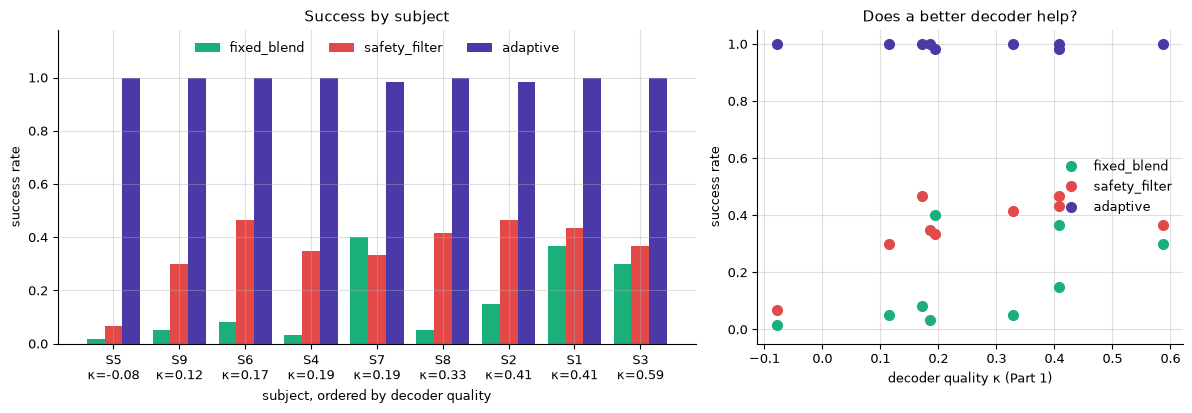

,pearson r,p,min success
fixed_blend,0.551,0.124,0.017
safety_filter,0.689,0.040,0.067
adaptive,-0.125,0.749,0.983


In [39]:
shown = ["fixed_blend", "safety_filter", "adaptive"]
by_subject = main[main.variant.isin(shown)].pivot_table(index="subject", columns="variant", values="success")
by_subject["kappa"] = part1["kappa"]
by_subject = by_subject.sort_values("kappa")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(by_subject))
for j, v in enumerate(shown):
    axes[0].bar(x + (j - 1) * 0.27, by_subject[v], 0.27, color=COLORS[v], label=v)
axes[0].set_xticks(x, [f"S{s}\nκ={k:.2f}" for s, k in by_subject.kappa.items()])
axes[0].set(ylabel="success rate", ylim=(0, 1.18), xlabel="subject, ordered by decoder quality",
            title="Success by subject")
axes[0].legend(frameon=False, loc="upper center", ncol=3)

corr = {}
for v in shown:
    axes[1].plot(by_subject.kappa, by_subject[v], "o", color=COLORS[v], ms=7, label=v)
    r, p = stats.pearsonr(by_subject.kappa, by_subject[v])
    corr[v] = {"pearson r": round(r, 3), "p": round(p, 3), "min success": round(by_subject[v].min(), 3)}
axes[1].set(xlabel="decoder quality κ (Part 1)", ylabel="success rate", ylim=(-0.05, 1.05),
            title="Does a better decoder help?")
axes[1].legend(frameon=False, loc="center right")
fig.tight_layout()
save_fig("14_s6_success_vs_kappa")
corr_table = pd.DataFrame(corr).T
corr_table.to_csv(TABLES / "success_vs_kappa.csv")
corr_table

**Reading it.** For the fixed blend and the safety filter, success **rises with decoder quality**: a better decoder gives a better wheelchair. Under adaptive that link is **broken**. Every subject reaches 0.98–1.00, **including subject 5, whose decoder is worse than chance** (κ < 0). Adaptive's correlation is small and not significant (r ≈ −0.13, p ≈ 0.75): all nine values are squeezed between 0.98 and 1.00, leaving almost no variation to correlate.

(The report gives the same values for adaptive: r = −0.125, p = 0.749.)

### 6.10 How much fixed authority is too much?

The fixed blend was also run at every α from 0 to 1 in steps of 0.1. The "knee" is where crashes rise fastest: the largest slope, computed by finite differences (`np.gradient`).

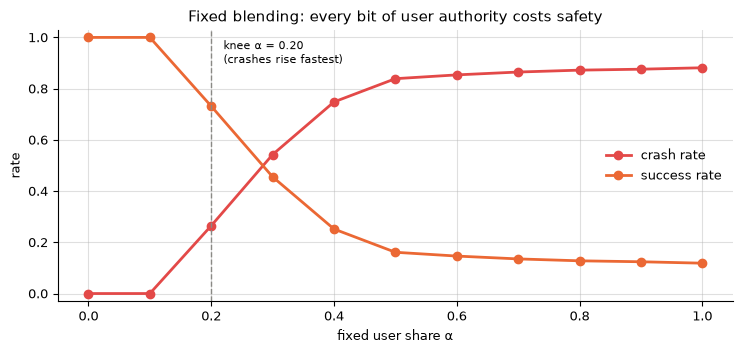

alpha_const,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
collisions,0.0,0.0,0.265,0.543,0.748,0.839,0.854,0.865,0.872,0.876,0.881
success,1.0,1.0,0.731,0.456,0.252,0.161,0.146,0.135,0.128,0.124,0.119
mean_alpha,0.0,0.1,0.200,0.300,0.400,0.500,0.600,0.700,0.800,0.900,1.000


In [40]:
sweep = log[log.condition == "alpha_sweep"].groupby("alpha_const").agg(
    collisions=("collisions", "mean"), success=("success", "mean"),
    mean_alpha=("mean_alpha", "mean"))
slopes = np.gradient(sweep.collisions.to_numpy(), sweep.index.to_numpy())
knee = sweep.index[int(np.argmax(slopes))]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sweep.index, sweep.collisions, "o-", color=RED, lw=2, label="crash rate")
ax.plot(sweep.index, sweep.success, "o-", color=ORANGE, lw=2, label="success rate")
ax.axvline(knee, color=GREY, ls="--", lw=1)
ax.text(knee + 0.02, 0.9, f"knee α = {knee:.2f}\n(crashes rise fastest)", fontsize=8)
ax.set(xlabel="fixed user share α", ylabel="rate", ylim=(-0.03, 1.03),
       title="Fixed blending: every bit of user authority costs safety")
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
save_fig("15_s6_alpha_sweep")
sweep.round(4).to_csv(TABLES / "alpha_sweep.csv")
sweep.round(3).T

**Reading it.** With a *fixed* split, safety holds only up to α = 0.1. Beyond that, crashes climb steeply, fastest around α = 0.2, and any constant share larger than that costs safety.

Note that a **fixed α = 0.1 is also 100% safe** and gives the user 10% of the control, close to adaptive's 12% average. So on these numbers, adaptive doesn't beat a well-chosen small fixed share. What differs is the **timing**: fixed 0.1 always gives the user 10%, while adaptive gives 0 near obstacles and 0.6 or more when the way is clear (6.6). Whether that timing matters to a real user is outside what the simulation measures, and it is a fair question for an examiner to ask.

### 6.11 Ablations: which ingredient does the work?

| ablation | what it changes |
|---|---|
| `no_risk_term` | risk forced to 0, so adaptive becomes plain confidence gating |
| `perfect_confidence` | confidence replaced by an oracle: 1.0 when the decision is right, 0.0 when wrong |
| `no_delay` | the user's reaction delay goes from 0.2 s to 0 |
| `no_burst_errors` | errors drawn as coin flips instead of from the chain |
| `confidence_decay` | confidence fades toward 0.25 as a decision gets older |
| `fixed_alpha` | every rule pinned to the fixed blend (a sanity check) |

In [41]:
ablations = ["no_risk_term", "perfect_confidence", "no_delay", "no_burst_errors", "confidence_decay"]
shown = ["adaptive", "safety_filter", "confidence_only"]
table = {"baseline": main.groupby("variant").success.mean()[shown]}
for name in ablations:
    table[name] = log[log.condition == f"ablation:{name}"].groupby("variant").success.mean()[shown]
table = pd.DataFrame(table).T
table.round(4).to_csv(TABLES / "ablations.csv")
print("success rate")
display(table.round(3))
print("change from baseline")
display((table - table.loc["baseline"]).round(3))

success rate


variant,adaptive,safety_filter,confidence_only
baseline,0.996,0.356,0.315
no_risk_term,0.796,0.119,0.315
perfect_confidence,0.996,0.356,0.507
no_delay,0.996,0.350,0.320
no_burst_errors,0.996,0.344,0.309
confidence_decay,1.000,0.356,0.569


change from baseline


variant,adaptive,safety_filter,confidence_only
baseline,0.000,0.000,0.000
no_risk_term,-0.200,-0.237,0.000
perfect_confidence,0.000,0.000,0.193
no_delay,0.000,-0.006,0.006
no_burst_errors,0.000,-0.011,-0.006
confidence_decay,0.004,0.000,0.254


**Reading it.** This is the project's key finding, and it isn't what the formula's name suggests.

- **Removing risk** drops adaptive from 1.00 to 0.80, and the safety filter from 0.36 to 0.12 (the filter also uses TTC). **Risk is doing the work.**
- **A perfect confidence signal**, an oracle that knows whether each decision was right, changes adaptive by **nothing**. Once risk is in the formula, confidence is almost decorative.
- A perfect confidence signal *does* help `confidence_only` (+0.19), where confidence is all it has. That shows the ceiling is higher with a perfect signal, not that the real signal is good enough to reach it.
- **Age decay** helps `confidence_only` by +0.25, but not because confidence is informative. Decaying toward 0.25 simply *lowers α*, handing back less control. The signal becomes *less* informative and performance *improves*, which is evidence **against** the signal. An earlier draft read this backwards (**Defect E**).
- **Part of why risk wins is the user model.** The model user aims straight at the goal, so many of its commands are *correctly decoded but unsafe*. Confidence cannot catch those by construction; risk can. An obstacle-aware user model could shift this balance.
- **Delay and bursts don't bind.** For bursts, that's because there are none (Section 2). For delay, the ablation proves little: removing 0.2 s from a loop whose real delay is several seconds is a small change. Section 7 gives the real reason.

This was all **re-checked after fixing Defect B** (confidence that was independent of correctness). Re-running with an informative confidence moved nothing, so the conclusion is no longer "an uninformative signal was ignored", but "an informative signal was available, and the controller still gained nothing measurable from it". Section 2.5 showed why: within one subject, confidence barely separates right from wrong.

### 6.12 The burstiness sweep, and what it cannot show

In [42]:
burst = log[log.condition == "burstiness"]
burst_table = burst.pivot_table(index="burst_multiplier", columns="variant", values="success")
burst_table.round(4).to_csv(TABLES / "burstiness.csv")
display(burst_table.round(3))
print("median decoder decisions per drive:")
burst.groupby("variant").commands_issued.median()

variant,adaptive,fixed_blend,safety_filter
burst_multiplier,,,
1.0,0.996,0.178,0.357
1.5,0.998,0.196,0.372
2.5,0.996,0.230,0.407
4.0,0.994,0.213,0.389


median decoder decisions per drive:


variant
adaptive          5.0
fixed_blend       5.0
safety_filter    30.0
Name: commands_issued, dtype: float64

**Reading it.** Adaptive stays at about 0.99 at every level. But this **cannot be read as robustness**. An adaptive or fixed-blend drive lasts only long enough for about **5 decoder decisions**, while at ×4 the imposed mean streak for subject 5 is about 21 decisions. A 21-long streak can't happen inside a 5-decision drive, so the experiment **lacks the time resolution** to test strong burstiness. "No effect seen" here means "could not be seen", not "no effect".

Only the safety filter, with about 30 decisions per (long) drive, can resolve streaks, and it's the one rule whose success moves with clustering.

---
## 7. Stability: how much delay can the loop take?

### The idea, without equations

In any feedback loop, **delay means acting on old information**. Steer hard on where the chair *was* and you overshoot; you notice late and correct hard the other way; you overshoot again. With enough delay, each swing is bigger than the last: the loop is **unstable**.

Here the user's path is delayed and the autopilot's path is not, and α sets how much weight the delayed path gets. So the question is:

> For each user share α, what is the longest loop delay $\tau_{max}$ before the loop starts to oscillate and grow?

### The result first

For the point mass (one axis):

- With the user alone (α = 1), the loop tolerates **τ_max = 0.529 s**.
- As α shrinks, τ_max grows.
- Below **α ≈ 0.4414**, the loop is stable for **any delay at all**: the undelayed autopilot is strong enough to hold the loop whatever the delayed user does. This is called **delay-independent stability**.

The point mass is used because its maths can be solved exactly. The same method is then applied to the wheelchair's heading loop (7.4).

### 7.1 The derivation

**One axis of the closed loop.** $z$ is the position error, $d$ the plant damping, $(K_p, K_d)$ the user's PD gains acting through the delay $\tau$, and $(K_1, K_2)$ the LQR gains from Section 3.2, acting without delay:

$$\ddot z + d\,\dot z + (1-\alpha)\big(K_1 z + K_2 \dot z\big) + \alpha\big(K_p\, z(t-\tau) + K_d\, \dot z(t-\tau)\big) = 0$$

**Laplace transform.** A delay of $\tau$ becomes the factor $e^{-\tau s}$:

$$s^2 + d\,s + (1-\alpha)(K_1 + K_2 s) + \alpha\,(K_p + K_d s)\,e^{-\tau s} = 0$$

This is the **characteristic equation**: the loop is stable when every root $s$ has a negative real part.

**Where stability is lost.** As $\tau$ grows, a root crosses the imaginary axis, at $s = j\omega$. Write the undelayed part as $A + jB$ and the delayed part as $C + jD$:

$$A = P_1 - \omega^2, \quad B = P_2\,\omega, \quad C = Q_1, \quad D = Q_2\,\omega \qquad\text{with}\quad P_1 = (1-\alpha)K_1,\ P_2 = d + (1-\alpha)K_2,\ Q_1 = \alpha K_p,\ Q_2 = \alpha K_d$$

The equation becomes $(A + jB) + (C + jD)\,e^{-j\omega\tau} = 0$. The factor $e^{-j\omega\tau}$ has magnitude 1, so the delay can only **rotate** the delayed term, never change its size. A crossing is therefore possible only if the two terms have **equal magnitude**, $A^2 + B^2 = C^2 + D^2$. Writing $X = \omega^2$, that is a **quadratic**:

$$X^2 + \big(P_2^2 - Q_2^2 - 2P_1\big)\,X + \big(P_1^2 - Q_1^2\big) = 0$$

Each positive root $X$ gives a crossing frequency $\omega = \sqrt{X}$. Solving for the rotation angle $\theta = \omega\tau$ gives

$$\cos\theta = -\frac{AC + BD}{C^2 + D^2}, \qquad \sin\theta = \frac{BC - AD}{C^2 + D^2}, \qquad \tau = \frac{\theta}{\omega},\ \theta \in [0, 2\pi)$$

and $\tau_{max}$ is the smallest such $\tau$. **No positive root means stable for every delay.**

**The delay-independent edge.** The constant term $P_1^2 - Q_1^2$ changes sign at

$$\alpha^* = \frac{K_1}{K_1 + K_p}$$

That α\* is the *exact* edge only if the middle coefficient $b$ is ≥ 0 there. Here $b(\alpha^*) < 0$, so α\* is only an **upper bound**, and the true edge is found by bisection just below it.

In [43]:
@dataclass(frozen=True)
class LoopGains:
    k1: float
    k2: float
    kp: float = 4.0
    kd: float = 2.0
    d: float = 1.0


def quadratic_coefficients(alpha, g):
    p1 = (1.0 - alpha) * g.k1
    p2 = g.d + (1.0 - alpha) * g.k2
    q1, q2 = alpha * g.kp, alpha * g.kd
    return float(p2 * p2 - q2 * q2 - 2.0 * p1), float(p1 * p1 - q1 * q1)   # b, c


def crossing_frequencies(alpha, g):
    b, c = quadratic_coefficients(alpha, g)
    disc = b * b - 4.0 * c
    if disc < 0.0:
        return np.zeros(0)
    root = math.sqrt(disc)
    xs = [0.5 * (-b - root), 0.5 * (-b + root)]
    return np.array(sorted(math.sqrt(x) for x in xs if x > 0.0))   # w = sqrt(X)


def crossing_delays(alpha, g):
    if alpha <= 0.0:
        return np.zeros(0)
    out = []
    for w in crossing_frequencies(alpha, g):
        a = (1.0 - alpha) * g.k1 - w * w
        b = (g.d + (1.0 - alpha) * g.k2) * w
        c = alpha * g.kp
        dd = alpha * g.kd * w
        denom = c * c + dd * dd
        theta = math.atan2((b * c - a * dd) / denom, -(a * c + b * dd) / denom)
        if theta < 0.0:
            theta += 2.0 * math.pi
        out.append(theta / w)
    return np.array(out)


def tau_max(alpha, g):
    taus = crossing_delays(alpha, g)
    return math.inf if taus.size == 0 else float(np.min(taus))


def is_delay_independent(alpha, g):
    return not math.isfinite(tau_max(alpha, g))


def alpha_star_closed_form(g):
    return float(g.k1 / (g.k1 + g.kp))


def b_at_alpha_star(g):
    return quadratic_coefficients(alpha_star_closed_form(g), g)[0]


def delay_independent_boundary(g, tol=1e-12):
    lo, hi = 0.0, alpha_star_closed_form(g)
    if b_at_alpha_star(g) >= 0.0:        # alpha* is exact
        return hi
    if not is_delay_independent(lo, g):
        return lo
    for _ in range(200):                 # bisection
        if hi - lo < tol:
            break
        mid = 0.5 * (lo + hi)
        if is_delay_independent(mid, g):
            lo = mid
        else:
            hi = mid
    return lo


def tau_max_curve(alphas, g):
    return np.array([tau_max(float(a), g) for a in alphas])


g = LoopGains(k1=K1, k2=K2, kp=cfg["operator.kp"], kd=cfg["operator.kd"],
              d=cfg["plants.double_integrator.damping"])
print(f"K1 = {g.k1:.6f}, K2 = {g.k2:.6f}, Kp = {g.kp}, Kd = {g.kd}, d = {g.d}")
print(f"alpha* = K1/(K1+Kp) = {alpha_star_closed_form(g):.7f}")
print(f"b(alpha*)           = {b_at_alpha_star(g):+.4f}  -> only an upper bound")
print(f"true edge           = {delay_independent_boundary(g):.7f}")
print(f"tau_max(alpha=1)    = {tau_max(1.0, g):.6f} s")

grid_alpha = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.45, 0.44, 0.3]
pd.DataFrame({"tau_max (s)": [tau_max(a, g) for a in grid_alpha]}, index=pd.Index(grid_alpha, name="alpha")).round(4).T

K1 = 3.162278, K2 = 1.885231, Kp = 4.0, Kd = 2.0, d = 1.0
alpha* = K1/(K1+Kp) = 0.4415184
b(alpha*)           = -0.0976  -> only an upper bound
true edge           = 0.4414251
tau_max(alpha=1)    = 0.529029 s


alpha,1.00,0.90,0.80,0.70,0.60,0.50,0.45,0.44,0.30
tau_max (s),0.529,0.6057,0.7114,0.8693,1.141,1.8147,3.5411,inf,inf


`inf` means stable at any delay. Just above the edge (α = 0.45) the loop already tolerates about 3.5 s, and the tolerance shoots up to infinity at the edge.

### 7.2 Checking the boundary three ways

A formula that hasn't been checked against something independent is only a claim.

**Check 1: against the `control` library at α = 1.** With the user alone, this is a classical loop with open-loop transfer function $L(s) = \dfrac{K_d s + K_p}{s^2 + d s}$, and its **delay margin** is the textbook quantity *phase margin ÷ crossover frequency*. The `control` package computes that independently.

In [44]:
def delay_margin_via_control(g):
    import control
    loop = control.tf([g.kd, g.kp], [1.0, g.d, 0.0])
    _gm, pm_deg, _wcg, wcp = control.margin(loop)
    pm = math.radians(float(pm_deg))
    return pm / float(wcp), pm, float(wcp)


try:
    margin, pm, wc = delay_margin_via_control(g)
    print(f"phase margin {math.degrees(pm):.3f} deg at crossover {wc:.6f} rad/s")
    print(f"formula        tau_max(1) = {tau_max(1.0, g):.15f} s")
    print(f"control package delay margin = {margin:.15f} s")
    print(f"difference = {abs(margin - tau_max(1.0, g)):.1e} s")
except ImportError:
    print("the 'control' package is not installed (pip install control); check 1 skipped")

phase margin 72.822 deg at crossover 2.402499 rad/s
formula        tau_max(1) = 0.529028964035817 s
control package delay margin = 0.529028964035817 s
difference = 2.2e-16 s


**Check 2: simulate the delayed equation directly.** A **DDE** (delay differential equation) is an ODE whose right-hand side uses values from the past. The integrator below steps it with RK4. Delayed values that fall between grid points are filled in by **Hermite interpolation**, a cubic that matches both the values and the slopes at the two neighbouring points, so the interpolation doesn't add error of its own. Just below τ_max the response should die out; just above it, it should grow.

`dde_growth_rate` measures the trend as the log-ratio of the peak amplitude late in the run to the peak in the middle, divided by the time between them: negative means decaying, positive means growing.

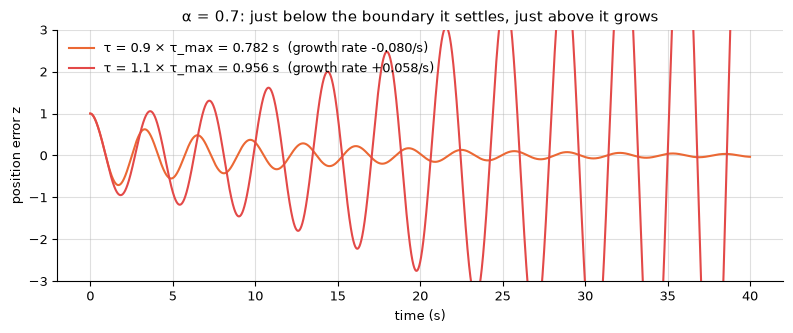

In [45]:
def _hermite(y0, y1, dy0, dy1, s, h):
    s2, s3 = s * s, s * s * s
    return ((2 * s3 - 3 * s2 + 1) * y0 + (s3 - 2 * s2 + s) * h * dy0
            + (-2 * s3 + 3 * s2) * y1 + (s3 - s2) * h * dy1)


def simulate_dde_axis(alpha, tau, g, *, h=2.0e-3, t_end=60.0, z0=1.0):
    a, d, k1, k2, kp, kd = alpha, g.d, g.k1, g.k2, g.kp, g.kd
    c_z, c_w = (1 - a) * k1, d + (1 - a) * k2
    n = int(round(t_end / h)) + 1
    z, w, dw = np.empty(n), np.empty(n), np.empty(n)
    z[0], w[0] = z0, 0.0

    def delayed(idx, off):              # z, w at time t - tau
        pos = idx + off - tau / h
        if pos <= 0.0:
            return z0, 0.0               # constant history
        i = int(math.floor(pos))
        s = pos - i
        if i + 1 > idx:
            return z[idx], w[idx]
        if s == 0.0:
            return z[i], w[i]
        return (_hermite(z[i], z[i + 1], w[i], w[i + 1], s, h),
                _hermite(w[i], w[i + 1], dw[i], dw[i + 1], s, h))

    def f(zz, ww, zt, wt):
        return ww, -c_w * ww - c_z * zz - a * (kp * zt + kd * wt)

    dw[0] = f(z[0], w[0], z0, 0.0)[1]
    for k in range(n - 1):              # RK4
        zt0, wt0 = delayed(k, 0.0)
        zt5, wt5 = delayed(k, 0.5)
        zt1, wt1 = delayed(k, 1.0)
        k1z, k1w = f(z[k], w[k], zt0, wt0)
        k2z, k2w = f(z[k] + .5 * h * k1z, w[k] + .5 * h * k1w, zt5, wt5)
        k3z, k3w = f(z[k] + .5 * h * k2z, w[k] + .5 * h * k2w, zt5, wt5)
        k4z, k4w = f(z[k] + h * k3z, w[k] + h * k3w, zt1, wt1)
        z[k + 1] = z[k] + (h / 6) * (k1z + 2 * k2z + 2 * k3z + k4z)
        w[k + 1] = w[k] + (h / 6) * (k1w + 2 * k2w + 2 * k3w + k4w)
        dw[k + 1] = f(z[k + 1], w[k + 1], zt1, wt1)[1]
        if not math.isfinite(z[k + 1]) or abs(z[k + 1]) > 1e12:
            z[k + 1:] = 1e12             # blew up
            break
    return np.arange(n) * h, z


def dde_growth_rate(alpha, tau, g, *, h=2e-3, t_end=60.0):
    t, z = simulate_dde_axis(alpha, tau, g, h=h, t_end=t_end)
    n = z.size
    mid, late = slice(int(0.40 * n), int(0.60 * n)), slice(int(0.80 * n), n)
    e_mid, e_late = float(np.max(np.abs(z[mid]))), float(np.max(np.abs(z[late])))
    if not math.isfinite(e_late):
        return math.inf
    span = float(t[late].mean() - t[mid].mean())
    return (math.log(max(e_late, 1e-300)) - math.log(max(e_mid, 1e-300))) / span


a = 0.7
tm = tau_max(a, g)
fig, ax = plt.subplots(figsize=(8, 3.4))
for factor, color in [(0.9, ORANGE), (1.1, RED)]:
    t_sim, z = simulate_dde_axis(a, factor * tm, g, t_end=40.0)
    rate = dde_growth_rate(a, factor * tm, g)
    ax.plot(t_sim, z, color=color, lw=1.5,
            label=f"τ = {factor} × τ_max = {factor * tm:.3f} s  (growth rate {rate:+.3f}/s)")
ax.set(xlabel="time (s)", ylabel="position error z", ylim=(-3, 3),
       title=f"α = {a}: just below the boundary it settles, just above it grows")
ax.legend(frameon=False)
fig.tight_layout()
save_fig("16_s7_dde_either_side")

**Check 3: find the boundary by simulation alone.** For a given α, `bisect_tau_max_dde` keeps simulating the DDE and halving the interval between a delay that settles and one that grows, until it has pinned down the switch point. No formula is involved. It takes about 10 s per α, so three values are checked here.

In [46]:
def bisect_tau_max_dde(alpha, g, *, lo=1e-3, hi=None, tol=1e-5, h=2e-3, t_end=60.0):
    if hi is None:
        exact = tau_max(alpha, g)
        hi = 3.0 * exact if math.isfinite(exact) else 10.0
    for _ in range(60):
        if hi - lo < tol:
            break
        mid = 0.5 * (lo + hi)
        if dde_growth_rate(alpha, mid, g, h=h, t_end=t_end) < 0.0:
            lo = mid                     # still stable
        else:
            hi = mid
    return 0.5 * (lo + hi)


started = time.time()
rows = []
for a in (0.6, 0.8, 1.0):
    found, exact = bisect_tau_max_dde(a, g), tau_max(a, g)
    rows.append({"alpha": a, "formula (s)": exact, "simulation (s)": found,
                 "relative error": abs(found - exact) / exact})
check3 = pd.DataFrame(rows).set_index("alpha")
check3.to_csv(TABLES / "tau_max_formula_vs_simulation.csv")
print(f"bisection took {time.time() - started:.0f} s")
check3.style.format({"formula (s)": "{:.6f}", "simulation (s)": "{:.6f}", "relative error": "{:.1e}"})

bisection took 20 s


,formula (s),simulation (s),relative error
alpha,,,
0.600000,1.140974,1.140974,1.4e-07
0.800000,0.711439,0.711440,1.0e-06
1.000000,0.529029,0.529031,4.0e-06


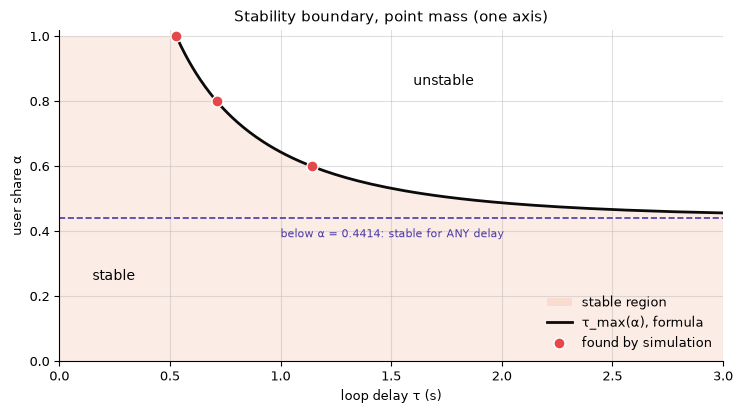

In [47]:
alphas = np.linspace(0, 1, 201)
curve = tau_max_curve(alphas, g)
pd.DataFrame({"alpha": alphas, "tau_max_s": curve}).to_csv(TABLES / "tau_max_curve.csv", index=False)
edge = delay_independent_boundary(g)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.fill_betweenx(alphas, 0, np.where(np.isfinite(curve), curve, 3.0),
                 color=ORANGE, alpha=0.12, lw=0, label="stable region")
ax.plot(curve, alphas, color=INK, lw=2, label="τ_max(α), formula")
ax.plot(check3["simulation (s)"], check3.index, "o", color=RED, ms=8, mec="white",
        label="found by simulation")
ax.axhline(edge, color=VIOLET, ls="--", lw=1.2)
ax.text(1.0, edge - 0.06, f"below α = {edge:.4f}: stable for ANY delay", color=VIOLET, fontsize=8)
ax.text(1.6, 0.85, "unstable", fontsize=10)
ax.text(0.15, 0.25, "stable", fontsize=10)
ax.set(xlim=(0, 3), ylim=(0, 1.02), xlabel="loop delay τ (s)", ylabel="user share α",
       title="Stability boundary, point mass (one axis)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save_fig("17_s7_stability_boundary")

The formula, the `control` library and direct simulation all agree, the first two to machine precision.

### 7.3 Padé: why the exact answer is preferred

The project brief asked for a **Padé (2,2) approximation**: replacing $e^{-\tau s}$ with a ratio of two quadratics, so that ordinary polynomial tools can be used:

$$e^{-\tau s} \approx \frac{1 - \tau s/2 + \tau^2 s^2/12}{1 + \tau s/2 + \tau^2 s^2/12}$$

Substituting turns the characteristic equation into a polynomial, whose roots NumPy can find; the boundary is then located by bisection on "any root in the right half-plane?". Because the exact solution is available, Padé is reported only as a comparison.

In [48]:
def pade22_tau_max(alpha, g):
    exact = tau_max(alpha, g)
    hi = 3.0 * exact if math.isfinite(exact) else 10.0

    def unstable(tau):
        num = np.array([tau * tau / 12.0, -tau / 2.0, 1.0])
        den = np.array([tau * tau / 12.0, tau / 2.0, 1.0])
        base = np.array([1.0, g.d + (1 - alpha) * g.k2, (1 - alpha) * g.k1])
        poly = np.polyadd(np.polymul(base, den), np.polymul(np.array([alpha * g.kd, alpha * g.kp]), num))
        return bool(np.max(np.roots(poly).real) > 0.0)

    lo = 1e-6
    if unstable(lo):
        return 0.0
    for _ in range(200):
        if not unstable(hi):
            hi *= 2.0
            if hi > 1e4:
                return math.inf
        else:
            break
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if unstable(mid):
            hi = mid
        else:
            lo = mid
        if hi - lo < 1e-9:
            break
    return 0.5 * (lo + hi)


pade = pd.DataFrame([{"alpha": a, "exact (s)": tau_max(a, g), "Padé(2,2) (s)": pade22_tau_max(a, g)}
                     for a in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)]).set_index("alpha")
pade["Padé over-estimate"] = (pade["Padé(2,2) (s)"] / pade["exact (s)"] - 1).map("{:.2%}".format)
pade.round(6).to_csv(TABLES / "pade_vs_exact.csv")
pade.round(4)

,exact (s),"Padé(2,2) (s)",Padé over-estimate
alpha,,,
1.0,0.5290,0.5308,0.33%
0.9,0.6057,0.6083,0.43%
0.8,0.7114,0.7155,0.58%
0.7,0.8693,0.8765,0.82%
0.6,1.1410,1.1558,1.30%
0.5,1.8147,1.8611,2.55%


Padé always **over-estimates** the margin: by 0.3% at α = 1, rising to about 2.5% at α = 0.5. It claims the loop can tolerate more delay than it really can, which is the dangerous direction.

### 7.4 The wheelchair's heading loop

The same machinery applies to the wheelchair's **turning** loop. Linearised, its turn-rate lag is $\tau_w\,\ddot\theta + \dot\theta = \omega_{cmd}$. Dividing by $\tau_w$ gives exactly the form above, with damping $1/\tau_w$ and every gain divided by $\tau_w$. The user's "gain" here is $k_{heading} = 2$, with no D term.

In [49]:
def unicycle_heading_gains(tau_w, k1, k2, kp, kd):
    return LoopGains(k1=k1 / tau_w, k2=k2 / tau_w, kp=kp / tau_w, kd=kd / tau_w, d=1.0 / tau_w)


gh = unicycle_heading_gains(cfg["plants.unicycle.tau_w"], k1=g.k1, k2=g.k2,
                            kp=cfg["plants.unicycle.k_heading"], kd=0.0)
heading_alpha_star = alpha_star_closed_form(gh)
b_h = b_at_alpha_star(gh)
print(f"heading loop: alpha* = {heading_alpha_star:.4f} (b(alpha*) = {b_h:+.3f}, so alpha* is "
      f"{'exact' if b_h >= 0 else 'only a bound'}; edge = {delay_independent_boundary(gh):.4f})")
print(f"heading loop: tau_max(alpha=1) = {tau_max(1.0, gh):.4f} s")

heading loop: alpha* = 0.6126 (b(alpha*) = +62.605, so alpha* is exact; edge = 0.6126)
heading loop: tau_max(alpha=1) = 0.6473 s


### 7.5 The honest part: does this boundary describe the simulated wheelchair?

**No, and the report says so** (Defect F in the report's section *Engineering Rigour: Bugs Caught, and How*). An earlier draft compared the user's 0.2 s reaction delay with the 0.529 s margin and called it "38% of the boundary". Both numbers were the wrong ones:

1. **The real loop delay is several seconds, not 0.2 s.** The boundary is about the *total* delay around the loop. The channel's 2 s sample-and-hold and its latency are inside the loop, so the command the chair acts on is typically 3–4 s old (Section 2.6 printed this). Measured over 319,345 simulation steps by a separate audit script, the effective delay is **3.84 s** (see the report).
2. **The right margin is the wheelchair's own, 0.647 s** (7.4), not the point mass's 0.529 s.

So the user-alone rule runs at about **5.8 times past the boundary**, and yet it doesn't oscillate itself to pieces. Why?

- **The structure differs.** The analysis assumes the delay sits on the *measurement* inside the loop: $K_p(\theta_{ref} - \theta(t-\tau))$. In the simulator, the user's *target* is delayed but the chair's own heading feedback is not: step 3 of 6.1 uses the delayed position with the *current* heading, so $\omega = k\,(\theta_{ref}(t-\tau) - \theta(t))$. A delayed **reference** can't destabilise a loop whose feedback is undelayed and stable. The speed command is also saturated in 77% of steps.
- **The crashes happen where delay can't matter.** 97% of the degradation happens at α below the heading loop's α\*, where the boundary says the loop is stable **for any delay whatsoever**.

The last point can be checked on the adaptive drive from Section 6:

In [50]:
alpha_trace = traced["adaptive"].trace["alpha"]
print(f"adaptive, subject 3, doorway: alpha < alpha* = {heading_alpha_star:.4f} "
      f"on {(alpha_trace < heading_alpha_star).mean():.0%} of steps")

adaptive, subject 3, doorway: alpha < alpha* = 0.6126 on 92% of steps


**Conclusion of Section 7.** The boundary is exact and verified for the loop it describes, but it doesn't transfer to the simulated wheelchair. The failures happen in a region where **no amount of delay could cause them**. That's a structural argument, not a margin ratio, and it points the same way as the ablations:

> **What limits this system is decoder *error*, not decoder *latency*.**

---
## 8. Summary

| part of the system | section | main result |
|---|---|---|
| BCI channel model | 2 | errors behave like coin flips (0 of 9 subjects bursty); confidence barely separates right from wrong within a subject; commands are 3–4 s old when used |
| Plant and operator models | 3, 4 | the wheelchair lags and can't move sideways; the model user drives well in open space but doesn't avoid obstacles |
| Autopilot | 5 | DWA scored on a navigation field (scoring the straight-line bearing gave 0% in the doorway) |
| Arbitration (sharing rules) | 5 | blending two safe commands can crash (the averaging trap); adaptive = confidence × (1 − risk) with hysteresis |
| Simulation study | 6 | user alone 12%; adaptive 99.6%, non-inferior to the autopilot but never better; risk does the work, not confidence |
| Stability analysis | 7 | exact τ_max(α), verified three ways; it doesn't bind in the simulator, where error, not latency, is the limit |

### What is measured and what is modelled

**Measured from real data:** decoder accuracy, confusion, calibration and latency for 9 subjects (Part 1), and every channel statistic in Section 2 derived from them.

**Modelled, with honest limits:**

- The user is a delayed PD controller that **always knows the goal, never adapts, and doesn't steer around obstacles**. This is the biggest gap, and it favours risk over confidence.
- **User agency is not measured.** The case for adaptive over the autopilot is that it gives control back; nothing here shows that this matters to a person.
- The command is a **continuous** rotated vector, not one of four discrete commands.
- Three hand-built 2-D rooms, static obstacles, a perfect map, exact position.
- Stability is analysed for a **frozen** α. Adaptive varies α, and its smoothing keeps the change slow, so the result is a guide, not a proof.

### Where to read more

- `report/report.pdf`: the full report, with the derivations, every result and its caveats.
- `src/part1_decoder.ipynb`: the decoder this notebook starts from.

### Run log

The last cell writes the checks and headline numbers from this run to `logs/part2_run.log`, so they can be compared with the report without opening the notebook.

In [51]:
lines = [
    "Part 2 run log",
    f"python packages: numpy {np.__version__}, pandas {pd.__version__}, scipy {scipy.__version__}, scikit-learn {sklearn.__version__}",
    "",
    "Section 2: bridge to Part 1 (largest difference from summary_by_subject.csv)",
    gap.round(6).to_string(),
    f"subjects with significant error bursts: {n_bursty} of {len(fits)}",
    f"pooled confidence AUC: {auc:.3f}",
    "",
    "Section 6.4: re-simulated drives vs saved log",
    f"drives re-simulated: {len(check)}",
    f"same outcome, time and decisions: {int(check['outcome identical'].sum())} of {len(check)}",
    f"largest relative difference in any metric: {check['largest relative difference'].max():.1e}",
    "",
    "Section 6.7: main comparison (540 drives per rule)",
    headline.round(3).to_string(),
    "",
    "Section 6.8: adaptive minus other rule, subject-level bootstrap",
    paired_table.round(3).to_string(),
    "",
    "Section 7: stability",
    f"LQR gains K1 = {g.k1:.6f}, K2 = {g.k2:.6f}",
    f"tau_max(alpha=1) = {tau_max(1.0, g):.6f} s",
    f"delay-independent below alpha = {delay_independent_boundary(g):.6f}",
    f"heading loop: alpha* = {heading_alpha_star:.4f}, tau_max(1) = {tau_max(1.0, gh):.4f} s",
    check3.to_string(),
]
(LOGS / "part2_run.log").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

Part 2 run log
python packages: numpy 2.5.2, pandas 3.0.5, scipy 1.18.1, scikit-learn 1.9.0

Section 2: bridge to Part 1 (largest difference from summary_by_subject.csv)
calib_acc            0.000044
kappa                0.000044
median_latency       0.000000
censored_fraction    0.000033
subjects with significant error bursts: 0 of 9
pooled confidence AUC: 0.676

Section 6.4: re-simulated drives vs saved log
drives re-simulated: 72
same outcome, time and decisions: 72 of 72
largest relative difference in any metric: 1.1e-09

Section 6.7: main comparison (540 drives per rule)
                 success  collisions  time_s  mean_alpha  intervention
variant                                                               
manual_only        0.119       0.881   9.338       1.000         0.000
autonomy_only      1.000       0.000  10.467       0.000         0.913
fixed_blend        0.161       0.839   9.779       0.500         0.933
confidence_only    0.315       0.683  10.165       0.387      